# 08 · Liquidity by hour: spot and perpetual, 48 h of snapshots and 12 months of `bookDepth`

Module **M3: liquidity** (Phase 1).

**Task.** Notebooks 06 and 07 measured one 45-minute window (Thursday 2026-11-19, 22:00–22:45
UTC). Here we ask how much the hour and the day change spread, depth and the cost of a round
trip, with two sources:

1. **Our collector**: one snapshot per minute of 4 Binance books (spot BTC/USDT, ETH/USDT,
   PENGU/USDT and the USDⓈ-M perpetual BTC/USDT:USDT) for ~48 h, Saturday 2026-11-21 23:46 UTC →
   Tuesday 2026-11-24 00:10 UTC. Raw levels, so we can compute anything, but only **one Sunday and
   one Monday**.
2. **Binance's public `bookDepth` files** (perpetual BTCUSDT only): depth at fixed distances from
   the mid every ~30 s, free, for years. Undocumented, so **Part 1 tests what the columns mean**
   against our own snapshots before anything is built on them.

Plus 1-minute spot candles (BTCUSDT, ETHUSDT) to compare **volume** with **depth**.

**Hypotheses (written before looking at the data; lab rule 1).** "I believe X because of Y":

| # | Belief (X) | Reason (Y) |
|---|---|---|
| H1 | Perp BTC depth is larger on weekdays 13–21 UTC than on weekend nights 21–03 UTC, in most months. | Market makers and trading desks in Europe and the US are at work in the first window; on weekend nights fewer firms quote, and with CME and banks closed hedging is harder, so they quote less size. |
| H2 | BTC and ETH spot spreads stay at about one tick at every hour; the hour changes depth, not spread. | Notebook 06: the spread sat at one tick ≥ 99.6% of the time; competition for queue priority keeps it there while there is any market maker. |
| H3 | For 10k–100k USDT on BTC/ETH spot the taker → taker round trip is fee-dominated at every hour; the hour only matters at 1M (and for PENGU). | Notebook 07: fees were ≥ 94% of the 100k cost in a calm hour; depth would have to fall many times over for impact to catch up. |
| H4 | Spot and perp BTC depth move together over the hours (positive correlation of their hourly profiles). | The same firms make both markets and hedge one with the other. |
| H5 | The hour of notebooks 06/07 (Thursday 22 UTC) was a typical hour for perp depth (between the 25th and 75th percentile of the 168 hour-of-week cells). | No reason to expect it to be special: it was chosen for convenience. |
| H6 | The hour with the thinnest book (lowest p10 depth) is the same hour in most months. | If thin hours come from who is at work (time zones), they should repeat; if they come from news, they should move around. |
| H7 | Volume is not a good proxy for depth: the hourly volume profile and the hourly depth profile are not strongly positively correlated. | Volume measures how much is traded (often when prices move); depth measures how much is offered to trade at a price. Market makers can pull size exactly when volume spikes. |

**What is fixed before looking (lab rule 4)**, and labeled *post-inspection* if changed later:
bands ±0.1% / ±0.2% / ±1% of the mid; spread in bps; depth in USDT; statistics median, p10, p90;
fees from notebook 07 (spot 0.10% / 0.10%, perp maker 0.02% / taker 0.05%); the 12-month window
**2025-11-24 → 2026-11-23**; the windows of H1 (Mon–Fri 13:00–20:59 UTC vs Sat–Sun 21:00–02:59
UTC, by the UTC calendar day); the Binance hack period **2026-10-29 → 2026-11-14** is labeled and
**kept out of every "normal" pattern**; the bookDepth pass criterion of Part 1.

**Times.** Everything is UTC. Mexico City (CDMX) is UTC−6 all year (no daylight saving since 2022);
it is shown as a label only, e.g. `14 UTC (08 CDMX)`. Weekdays are UTC calendar days, so "Monday
03 UTC" is still Sunday evening in Mexico City.

## 1. Setup

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.binance_vision import (book_depth_path, klines_periods, read_book_depth_zip,
                                     read_klines_zip, spot_klines_path)
from src.data.order_book import default_markets, load_snapshots
from src.execution_costs import STATUS_FILLED
from src.liquidity import (BUSINESS, WEEKDAYS, WEEKEND_NIGHT, add_time_labels, add_total_depth,
                           book_depth_side_totals, book_depth_wide, cdmx_hour, cell_percentile,
                           check_cumulative, clean_book_depth, daily_from_minutes, hour_label, implied_price,
                           in_window, lagged_correlation, match_nearest, process_collector_run,
                           quantile, ratio_by_month, resample_hourly, stress_table, week_heatmap,
                           window_month)
from src.order_book import snapshot_metrics

RUN_DIR = REPO_ROOT / "data" / "collector" / "2026-11-21"      # the 48 h collector run
SESSION_06 = REPO_ROOT / "data" / "06_order_book" / "session"   # notebook 06's 45 minutes
VISION = REPO_ROOT / "data" / "binance_vision"                  # scripts/download_binance_vision.py
CACHE = REPO_ROOT / "data" / "08_liquidity"
CACHE.mkdir(exist_ok=True)

MARKETS = [m.label for m in default_markets("PENGU/USDT")]
PERP, BTC_SPOT, ETH_SPOT, PENGU = ("perp BTC/USDT:USDT", "spot BTC/USDT", "spot ETH/USDT",
                                   "spot PENGU/USDT")
# Round-trip sizes per leg (USDT): PENGU's book is much thinner (notebook 07), so smaller sizes.
SIZES = {m: (1_000.0, 10_000.0, 100_000.0) if m == PENGU else (10_000.0, 100_000.0, 1_000_000.0)
         for m in MARKETS}
# Same fees as notebook 07, fractions of the notional (0.001 = 0.10%).
SPOT_REGULAR = {"maker": 0.0010, "taker": 0.0010}
USDM_REGULAR = {"maker": 0.0002, "taker": 0.0005}
FEES = {m: (SPOT_REGULAR if m.startswith("spot") else USDM_REGULAR) for m in MARKETS}

RUN_DAYS = {pd.Timestamp("2026-11-22", tz="UTC"): "Sun 2026-11-22",
            pd.Timestamp("2026-11-23", tz="UTC"): "Mon 2026-11-23"}
WINDOW_12M = ("2025-11-24", "2026-11-23")
POST_HACK = (pd.Timestamp("2026-10-29", tz="UTC"), pd.Timestamp("2026-11-14", tz="UTC"))
STRESS_10_10 = ("2025-10-06", "2025-10-14")
DAY_06 = "2026-11-19"
USDT_M = 1e6

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.DataFrame(FEES).T.mul(100).add_suffix(" (%)")

,maker (%),taker (%)
spot BTC/USDT,0.10,0.10
spot ETH/USDT,0.10,0.10
spot PENGU/USDT,0.10,0.10
perp BTC/USDT:USDT,0.02,0.05


How to read it: one row per market, the maker and taker fee (percent of the notional) that every
round trip below uses, copied from notebook 07. A taker → taker round trip pays the taker fee
twice: 20 bps on spot, 10 bps on the perpetual.

## 2. Part 0 · Inventory of the collector run and stress label

### 2.1 What the collector brought

`process_collector_run` (in `src/liquidity.py`) reads the run **one hour file and one market at a
time** and applies the same functions as notebooks 06 and 07 to every snapshot:
`snapshot_metrics` (spread, depth per band and side, truncation flags) and
`market_order_legs` + `round_trips` (taker → taker, the 07 code and fees). The results are cached
in `data/08_liquidity/`; delete those files to recompute (~5 minutes).

In [2]:
metrics_path, rt_path = CACHE / "collector_metrics.parquet", CACHE / "collector_round_trips.parquet"
if not (metrics_path.exists() and rt_path.exists()):
    _m, _rt = process_collector_run(RUN_DIR, MARKETS, SIZES, FEES)
    _m.to_parquet(metrics_path)
    _rt.to_parquet(rt_path)
metrics = add_time_labels(add_total_depth(pd.read_parquet(metrics_path)), "local_receive_utc")
rt = add_time_labels(pd.read_parquet(rt_path), "local_receive_utc")

log_lines = (RUN_DIR / "collector.log").read_text(encoding="utf-8").splitlines()
end_line = next(line for line in reversed(log_lines) if "  end: " in line)
run_summary = json.loads(end_line.split("  end: ", 1)[1])
print("collector summary:", {k: v for k, v in run_summary.items() if k not in ("start_ms", "end_ms")})

m_sorted = metrics.sort_values("local_receive_utc")
gap_s = m_sorted.groupby("market")["local_receive_utc"].diff().dt.total_seconds()
inventory = m_sorted.assign(gap_s=gap_s).groupby("market").agg(
    snapshots=("mid", "size"),
    first_receive_utc=("local_receive_utc", "min"), last_receive_utc=("local_receive_utc", "max"),
    median_gap_s=("gap_s", "median"), min_gap_s=("gap_s", "min"), max_gap_s=("gap_s", "max"),
    gaps_over_90s=("gap_s", lambda x: int((x > 90).sum())),
    bid_levels_min=("n_levels_bid", "min"), ask_levels_min=("n_levels_ask", "min"),
    median_mid=("mid", "median")).reindex(MARKETS)
start, end = inventory["first_receive_utc"].min(), inventory["last_receive_utc"].max()
print(f"run: {start:%a %Y-%m-%d %H:%M:%S} UTC ({start.tz_convert('America/Mexico_City'):%a %H:%M} "
      f"CDMX) -> {end:%a %Y-%m-%d %H:%M:%S} UTC ({end.tz_convert('America/Mexico_City'):%a %H:%M} CDMX)")
inventory

collector summary: {'rounds': 2905, 'skipped_slots': 0, 'snapshots': 11620, 'failures': 0, 'max_used_weight': {'binance': 750, 'binanceusdm': 20}}
run: Sat 2026-11-21 23:46:29 UTC (Sat 17:46 CDMX) -> Tue 2026-11-24 00:10:29 UTC (Mon 18:10 CDMX)


,snapshots,first_receive_utc,last_receive_utc,median_gap_s,min_gap_s,max_gap_s,gaps_over_90s,bid_levels_min,ask_levels_min,median_mid
market,,,,,,,,,,
spot BTC/USDT,2905,2026-11-21 23:46:29.106+00:00,2026-11-24 00:10:28.485+00:00,60.0,58.199,61.848,0,5000,5000,61072.295000
spot ETH/USDT,2905,2026-11-21 23:46:29.393+00:00,2026-11-24 00:10:28.694+00:00,60.0,58.171,61.850,0,5000,5000,1717.575000
spot PENGU/USDT,2905,2026-11-21 23:46:29.625+00:00,2026-11-24 00:10:28.891+00:00,60.0,57.875,63.970,0,283,5000,0.004292
perp BTC/USDT:USDT,2905,2026-11-21 23:46:30.336+00:00,2026-11-24 00:10:29.082+00:00,60.0,35.872,84.008,0,1000,1000,61040.550000


How to read it: the first line is the collector's own summary (rounds, slots skipped, snapshots,
failed requests, highest weight used per minute). The table has one row per market: snapshots
kept, first and last receive time (UTC), the seconds between consecutive snapshots of that
market (median, min, max; 60 if the schedule held), how many gaps were longer than 90 s (a missed
round would show as ~120 s), the fewest levels received per side (5000 / 1000 = the endpoint's
maximum every time), and the median mid price in USDT (a sanity check of units: BTC around
60,000, ETH a few thousand, PENGU a fraction of a cent).

In [3]:
coverage = (metrics.assign(hour=metrics["local_receive_utc"].dt.floor("1h"))
            .groupby(["hour", "market"]).size().unstack("market").reindex(columns=MARKETS))
full = coverage.iloc[1:-1]            # first and last hours are partial (start 23:46, end 00:10)
print(f"{len(coverage)} UTC hours touched; first {coverage.index[0]:%a %H:%M}, last "
      f"{coverage.index[-1]:%a %H:%M} UTC")
print(f"full hours (all but the first and last): {len(full)}; snapshots per market and hour: "
      f"min {int(full.min().min())}, max {int(full.max().max())}")
print("partial hours:")
coverage.iloc[[0, -1]]

50 UTC hours touched; first Sat 23:00, last Tue 00:00 UTC
full hours (all but the first and last): 48; snapshots per market and hour: min 60, max 60
partial hours:


market,spot BTC/USDT,spot ETH/USDT,spot PENGU/USDT,perp BTC/USDT:USDT
hour,,,,
2026-11-21 23:00:00+00:00,14,14,14,14
2026-11-24 00:00:00+00:00,11,11,11,11


How to read it: snapshots per UTC hour and market. With one round per minute a full hour has 60
(a snapshot whose receive time slips past the hour boundary can make it 59 / 61). The first hour
(Saturday 23:xx) and the last (Tuesday 00:xx) are partial and are **left out of every hourly
table** below, which use the two full UTC days: Sunday 2026-11-22 and Monday 2026-11-23.

### 2.2 Stress label of the two days

**Rule (fixed before looking):** with daily BTC/USDT spot candles, compute each day's return
(close / previous close − 1) and range ((high − low) / close), and their percentile against the
90 days before. If either percentile (|return| or range) is above 90 for either day, the run is
labeled **"stress weekend"**; otherwise **"normal"**.

The daily candles are built from the 1-minute spot candles of data.binance.vision (needed in
Part 4 anyway; timestamps in **microseconds**, see `src/data/binance_vision.py`) and checked
against the daily candles stored by earlier notebooks (`data/binance_spot_1d/`, from ccxt) where
both exist.

In [4]:
def load_minute_klines(symbol, start=WINDOW_12M[0], end=WINDOW_12M[1]):
    # 1-minute spot candles over [start, end] (UTC days), cached as one Parquet file.
    path = CACHE / f"{symbol}_1m_{start}_{end}.parquet"
    if not path.exists():
        frames = []
        for period in klines_periods(start, end):
            rel = spot_klines_path(symbol, "1m", period)
            frames.append(read_klines_zip(VISION / rel))
        df = pd.concat(frames).sort_index()
        df.to_parquet(path)
    df = pd.read_parquet(path)
    lo, hi = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)
    df = df[(df.index >= lo) & (df.index < hi)]
    assert df.index.is_unique and df.index.is_monotonic_increasing
    return df


klines = {s: load_minute_klines(s) for s in ("BTCUSDT", "ETHUSDT")}
for s, k in klines.items():
    expected = pd.date_range(k.index[0], k.index[-1], freq="1min")
    print(f"{s}: {len(k):,} 1-min candles, {k.index[0]} -> {k.index[-1]}, missing "
          f"{len(expected.difference(k.index))}, zero-volume {int((k['volume'] == 0).sum())}")

btc_daily = daily_from_minutes(klines["BTCUSDT"])
ccxt_daily = pd.read_parquet(REPO_ROOT / "data" / "binance_spot_1d" / "BTCUSDT_1d_from_2018-01-01.parquet")
both = btc_daily[["open", "high", "low", "close"]].merge(
    ccxt_daily[["open", "high", "low", "close"]], left_index=True, right_index=True,
    suffixes=("", "_ccxt"), how="inner")
rel_diff = max((both[c] / both[f"{c}_ccxt"] - 1).abs().max() for c in ("open", "high", "low", "close"))
print(f"daily candles from 1-min vs ccxt daily: {len(both)} common days, largest relative "
      f"difference in O/H/L/C = {rel_diff:.2e}")
print(f"days in the minute data with fewer than 1440 candles: "
      f"{int((btc_daily['minutes'] < 1440).sum())}")

stress = stress_table(btc_daily, ["2026-11-22", "2026-11-23"], lookback=90)
RUN_LABEL = "stress weekend" if stress["stress"].any() else "normal"
print(f"run label: {RUN_LABEL!r}")
stress.round(2)

BTCUSDT: 525,600 1-min candles, 2025-11-24 00:00:00+00:00 -> 2026-11-23 23:59:00+00:00, missing 0, zero-volume 0
ETHUSDT: 525,600 1-min candles, 2025-11-24 00:00:00+00:00 -> 2026-11-23 23:59:00+00:00, missing 0, zero-volume 0
daily candles from 1-min vs ccxt daily: 355 common days, largest relative difference in O/H/L/C = 0.00e+00
days in the minute data with fewer than 1440 candles: 0
run label: 'stress weekend'


,close,high,low,return (%),range (%),|return| percentile,range percentile,prior p90 |return| (%),prior p90 range (%),prior days,stress
day,,,,,,,,,,,
2026-11-22,61271.08,61669.99,58768.51,1.75,4.74,70.0,85.56,3.5,5.94,90,False
2026-11-23,61270.93,64603.12,60386.00,-0.00,6.88,0.0,94.44,3.5,5.94,90,True


How to read it: the first lines check the minute data (candles, first/last, missing minutes,
minutes with no trade) and that daily candles built from them match the ccxt daily candles of
earlier notebooks (a difference near 1e-16 means identical up to float rounding). The table has
one row per day: BTC/USDT spot close, high and low (USDT); the day's return and range in %; the
share of the previous 90 days with a smaller |return| / range (the percentile); the p90 of those
90 days for reference; and `stress` = True if either percentile is above 90. The label printed
above applies to the whole run.

## 3. Part 1 · Validate the `bookDepth` format against our own snapshots

`bookDepth` files (perpetual BTCUSDT, `data/futures/um/daily/bookDepth/`, one zip per UTC day)
are not documented. Notebook 06 inferred four things; each is tested here:

1. **Cumulative** depth from the mid up to each percentage, not depth of each band alone: then on
   every row the values must grow from ±0.2% to ±5%.
2. **Sign**: negative percentage = bids (below the mid), positive = asks.
3. **Units**: `depth` in BTC and `notional` in USDT. Then `notional / depth` is an average price
   that must sit just below the mid for bids and just above for asks, within the band.
4. **Time zone**: `timestamp` (text without zone) is UTC. Test: correlation of the hourly series
   of ±0.2% depth against our collector's, shifting bookDepth by −8 … +8 h; the best shift must be 0.

Then a direct comparison at ±0.2% per side: each bookDepth timestamp is matched with the nearest
collector snapshot of the perpetual (≤ 30 s apart). The perp snapshot has only 1000 levels per
side, which may end **before** ±0.2% (`complete_0.2pct_<side>` = False): there the collector value
is a lower bound and is reported separately.

**Pass criterion (fixed before looking):** the median ratio bookDepth / collector at ±0.2% is
between **0.8 and 1.25 on both sides**, and the best time shift is **0 h**. If it fails, the notebook
stops here: every perp conclusion of Parts 2–4 depends on it.

In [5]:
BD_DIR = VISION / "futures" / "um" / "daily" / "bookDepth" / "BTCUSDT"


def read_book_depth_day(day):
    return read_book_depth_zip(VISION / book_depth_path("BTCUSDT", day))


bd_raw = {day: read_book_depth_day(day) for day in ("2026-11-22", "2026-11-23", DAY_06)}
print("raw columns and types:", dict(bd_raw["2026-11-22"].dtypes.astype(str)))
rows = []
for day, raw in bd_raw.items():
    ts = raw["timestamp_utc"].drop_duplicates().sort_values()
    step = ts.diff().dt.total_seconds()
    rows.append({"day": day, "rows": len(raw), "timestamps": len(ts),
                 "percentages": " ".join(f"{p:g}" for p in sorted(raw["percentage"].unique())),
                 "rows per timestamp": raw.groupby("timestamp_utc").size().unique().tolist(),
                 "first": ts.iloc[0], "last": ts.iloc[-1],
                 "median step (s)": step.median(), "max step (s)": step.max()})
display(pd.DataFrame(rows).set_index("day"))
bd_raw["2026-11-22"].head(12)

raw columns and types: {'timestamp_utc': 'datetime64[ms, UTC]', 'percentage': 'float64', 'depth': 'float64', 'notional': 'float64'}


,rows,timestamps,percentages,rows per timestamp,first,last,median step (s),max step (s)
day,,,,,,,,
2026-11-22,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-22 00:00:01+00:00,2026-11-22 23:59:30+00:00,30.0,35.0
2026-11-23,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-23 00:00:01+00:00,2026-11-23 23:59:30+00:00,30.0,35.0
2026-11-19,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-19 00:00:01+00:00,2026-11-19 23:59:30+00:00,30.0,39.0


,timestamp_utc,percentage,depth,notional
0,2026-11-22 00:00:01+00:00,-5.0,6021.235,3.570688e+08
1,2026-11-22 00:00:01+00:00,-4.0,5764.999,3.423421e+08
2,2026-11-22 00:00:01+00:00,-3.0,5470.837,3.252650e+08
3,2026-11-22 00:00:01+00:00,-2.0,4729.326,2.816994e+08
4,2026-11-22 00:00:01+00:00,-1.0,1918.420,1.148288e+08
5,2026-11-22 00:00:01+00:00,-0.2,375.767,2.259244e+07
6,2026-11-22 00:00:01+00:00,0.2,281.760,1.697864e+07
7,2026-11-22 00:00:01+00:00,1.0,1624.858,9.834619e+07
8,2026-11-22 00:00:01+00:00,2.0,4760.500,2.897567e+08
9,2026-11-22 00:00:01+00:00,3.0,5855.290,3.573851e+08


How to read it: first the raw column names and types (after parsing `timestamp` as UTC; the other
three come exactly as in the file). The table has one row per day downloaded: rows, distinct
timestamps, the percentages present (negative and positive), how many rows each timestamp has
(12 = one per percentage), the first and last timestamp, and the seconds between timestamps
(median and largest; a large maximum is a hole in Binance's file). The last table is the first
timestamp of 2026-11-22, raw: `percentage` in %, `depth` and `notional` as published.

In [6]:
bd_wide = {day: book_depth_wide(raw) for day, raw in bd_raw.items()}
cum = pd.concat({(day, field): check_cumulative(w, field) for day, w in bd_wide.items()
                 for field in ("notional", "depth")}, names=["day", "field", "side"])
cum[["timestamps", "monotonic (% of timestamps)", "smallest step"]]

timestamps monotonic (% of timestamps)  smallest step
day        field    side                                                                  
2026-11-22 notional bid (negative %)       2880                       100.0  10989617.0235
                    ask (positive %)       2880                       100.0  13645183.0119
           depth    bid (negative %)       2880                       100.0        185.188
                    ask (positive %)       2880                       100.0        212.061
2026-11-23 notional bid (negative %)       2880                       100.0   3264113.3396
                    ask (positive %)       2880                       100.0   6196631.1187
           depth    bid (negative %)       2880                       100.0         53.221
                    ask (positive %)       2880                       100.0         96.291
2026-11-19 notional bid (negative %)       2880                       100.0  24564540.9626
                    ask (positive %)       2880                       100.0  15041616.2612
           depth    bid (negative %)       2880                       100.0        413.694
                    ask (positive %)       2880                       100.0        238.208

How to read it (assumption 1): one row per day, field and side. `monotonic` is the share of
timestamps in which the value never decreases when moving away from the mid
(0.2 → 1 → 2 → 3 → 4 → 5 %). `smallest step` is the smallest change between neighboring
percentages over all timestamps: if it is ≥ 0, no row ever shrinks outward, which is what a
**cumulative** sum must do. Per-band values (e.g. only the orders between 1% and 2%) would go up
and down.

In [7]:
perp = metrics[metrics["market"] == PERP].sort_values("local_receive_utc")
perp_cols = ["local_receive_utc", "mid", "depth_0.2pct_bid_usdt", "depth_0.2pct_ask_usdt",
             "depth_0.2pct_total_usdt", "complete_0.2pct_bid", "complete_0.2pct_ask"]
bd_run = pd.concat([bd_wide["2026-11-22"], bd_wide["2026-11-23"]]).sort_index()
bd_run_sides = book_depth_side_totals(bd_run, pcts=(0.2, 1.0)).reset_index()
matched = match_nearest(bd_run_sides, perp[perp_cols], tolerance="30s")
print(f"bookDepth timestamps 2026-11-22/23: {len(bd_run_sides):,}; matched with a collector "
      f"snapshot within 30 s: {len(matched):,}; |gap| median {matched['gap_s'].abs().median():.1f} s, "
      f"max {matched['gap_s'].abs().max():.1f} s")

# Assumptions 2 and 3: implied average price notional / depth versus the collector's mid
price = implied_price(bd_run).reset_index().merge(matched[["timestamp_utc", "mid"]], on="timestamp_utc")
units = pd.DataFrame({p: (price[p] / price["mid"] - 1) * 100 for p in sorted(bd_run["notional"].columns)})
unit_table = units.describe(percentiles=[0.5]).T[["count", "min", "50%", "max"]]
unit_table.columns = ["n", "min (%)", "median (%)", "max (%)"]
unit_table["inside the band"] = [((units[p] <= 0) & (units[p] >= p)).mean() * 100 if p < 0 else
                                 ((units[p] >= 0) & (units[p] <= p)).mean() * 100 for p in units]
unit_table.index.name = "percentage"
unit_table.round(4)

bookDepth timestamps 2026-11-22/23: 5,760; matched with a collector snapshot within 30 s: 5,719; |gap| median 1.9 s, max 30.0 s


,n,min (%),median (%),max (%),inside the band
percentage,,,,,
-5.0,5719.0,-3.2157,-1.5235,-0.7354,100.0000
-4.0,5719.0,-3.0557,-1.3197,-0.5977,100.0000
-3.0,5719.0,-2.9125,-1.1715,-0.5059,100.0000
-2.0,5719.0,-2.8103,-1.0471,-0.4209,99.9650
-1.0,5719.0,-2.1974,-0.5265,0.1535,99.7727
-0.2,5719.0,-1.8477,-0.1109,0.5683,92.3063
0.2,5719.0,-1.6506,0.1101,0.7878,92.2014
1.0,5719.0,-1.2445,0.5112,1.1598,99.7377
2.0,5719.0,-0.7269,1.0746,1.8583,99.9825


How to read it (assumptions 2 and 3): the first line says how many bookDepth timestamps found a
collector snapshot of the perpetual within 30 s, and how far apart they were. The table has one
row per bookDepth percentage. Each value is `notional / depth` divided by the collector's mid,
minus 1, in %: where the average price of that depth sits relative to the mid. If `depth` is in
BTC and `notional` in USDT, this is a price near 60,000 USDT and the numbers are small
(fractions of a %); if both were USDT (or both BTC) the ratio would be 1 and every row would read
about −100% or +5 million %. `inside the band` = share of timestamps where the average price lies
between the mid and the band's edge on the expected side (below the mid for negative
percentages = bids, above for positive = asks). A cumulative band of ±p% must average less than
p% away.

In [8]:
side_rows = []
for side, other in (("bid", "ask"), ("ask", "bid")):
    complete = matched[f"complete_0.2pct_{side}"].astype(bool)
    ratio = matched[f"0.2pct_{side}"] / matched[f"depth_0.2pct_{side}_usdt"]
    swapped = matched[f"0.2pct_{side}"] / matched[f"depth_0.2pct_{other}_usdt"]
    side_rows.append({
        "side": side, "matched": len(ratio),
        "collector reaches ±0.2% (% of matched)": 100 * complete.mean(),
        "median ratio bookDepth / collector": ratio.median(),
        "p10 ratio": ratio.quantile(0.1), "p90 ratio": ratio.quantile(0.9),
        "median ratio, complete snapshots only": ratio[complete].median(),
        "median ratio, incomplete only (collector = lower bound)": ratio[~complete].median(),
        "median |log ratio|, this side": np.log(ratio).abs().median(),
        "median |log ratio|, sides swapped": np.log(swapped).abs().median()})
side_check = pd.DataFrame(side_rows).set_index("side")
side_check.T.round(4)

side,bid,ask
matched,5719.0000,5719.0000
collector reaches ±0.2% (% of matched),99.9301,100.0000
median ratio bookDepth / collector,0.9974,0.9961
p10 ratio,0.8989,0.8938
p90 ratio,1.1047,1.1162
"median ratio, complete snapshots only",0.9974,0.9961
"median ratio, incomplete only (collector = lower bound)",1.0087,NaN
"median |log ratio|, this side",0.0483,0.0519
"median |log ratio|, sides swapped",0.1152,0.1177


How to read it (direct comparison at ±0.2%, and assumption 2 again): one column per side.
`matched` = pairs (bookDepth timestamp, nearest collector snapshot ≤ 30 s). `collector reaches
±0.2%` = share of those snapshots whose 1000 levels went past ±0.2% of the mid (if not, the
collector's number is a lower bound and the ratio is biased up). The ratio is bookDepth's
`notional` at −0.2% (bids) or +0.2% (asks) divided by the collector's USDT depth within ±0.2% on
that side: 1 = identical. p10 and p90 show the spread of the ratio across timestamps: the two
sources are not taken at the same instant (up to 30 s apart) and depth near the mid changes a lot
in seconds (notebook 06, section 9). The last two rows compare the **typical size of the error**
(|log ratio|, 0 = equal) when bids are paired with bids versus with asks: if the sign convention
were reversed, the swapped pairing would fit better.

best shift: +0 h (corr 0.998); corr at 0 h 0.998; next best 0.822 at +1 h


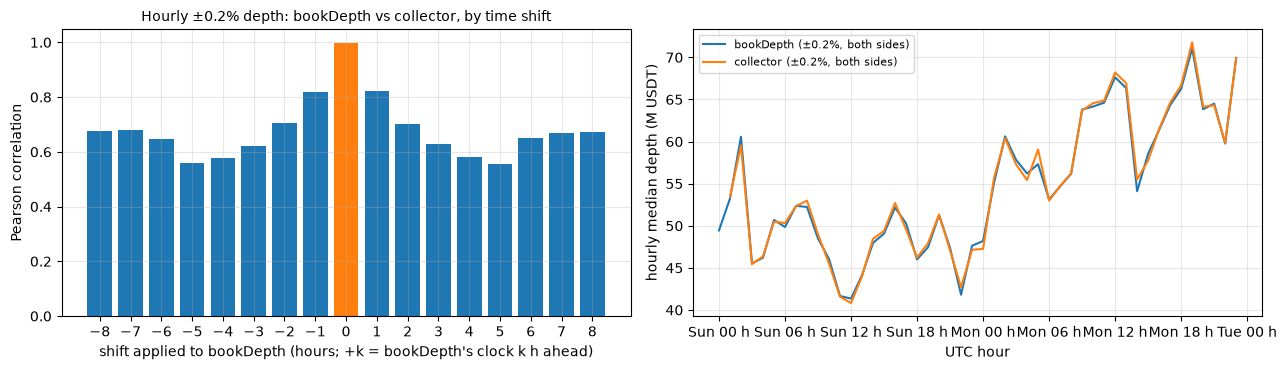

lag_h,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
corr,0.675,0.68,0.649,0.56,0.579,0.621,0.707,0.819,0.998,0.822,0.701,0.63,0.58,0.556,0.652,0.669,0.674
n,39.000,40.00,41.000,42.00,43.000,44.000,45.000,46.000,47.000,47.000,46.000,45.00,44.00,43.000,42.000,41.000,40.000


In [9]:
bd_hourly = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["0.2pct_total"]])["0.2pct_total"]
col_hourly = resample_hourly(perp.set_index("local_receive_utc")[["depth_0.2pct_total_usdt"]])
col_hourly = col_hourly.loc[col_hourly.index.isin(bd_hourly.index), "depth_0.2pct_total_usdt"]
col_hourly = col_hourly.iloc[1:]                 # drop the partial first hour (Sat 23:46-23:59)
lags = lagged_correlation(bd_hourly, col_hourly, range(-8, 9))
BEST_LAG = int(lags["corr"].idxmax())
print(f"best shift: {BEST_LAG:+d} h (corr {lags['corr'].max():.3f}); corr at 0 h "
      f"{lags.loc[0, 'corr']:.3f}; next best {lags['corr'].drop(BEST_LAG).max():.3f} at "
      f"{int(lags['corr'].drop(BEST_LAG).idxmax()):+d} h")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(lags.index, lags["corr"], color=["tab:orange" if l == BEST_LAG else "tab:blue" for l in lags.index])
axes[0].set_xlabel("shift applied to bookDepth (hours; +k = bookDepth's clock k h ahead)")
axes[0].set_ylabel("Pearson correlation")
axes[0].set_title("Hourly ±0.2% depth: bookDepth vs collector, by time shift", fontsize=10)
axes[0].set_xticks(lags.index)
axes[0].grid(alpha=0.3)
axes[1].plot(bd_hourly.index, bd_hourly / USDT_M, label="bookDepth (±0.2%, both sides)")
axes[1].plot(col_hourly.index, col_hourly / USDT_M, label="collector (±0.2%, both sides)")
axes[1].set_ylabel("hourly median depth (M USDT)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%a %H h", tz="UTC"))
axes[1].set_xlabel("UTC hour")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()
lags.T.round(3)

How to read it (assumption 4): left, one bar per time shift from −8 to +8 hours; the height is
the correlation between the hourly median ±0.2% depth (both sides) of bookDepth, moved by that
many hours, and the collector's (n = number of hours that overlap, in the table). If the
timestamps were, say, UTC+8 (Asia), the best bar would be at +8. The best one is orange. Right,
the two hourly series in millions of USDT over the run: if the sources agree they rise and fall
together, at about the same level.

In [10]:
# The same comparison on notebook 06's window (2026-11-19 22:00-22:45 UTC, snapshots every 10 s)
levels_06 = load_snapshots(SESSION_06, markets=[PERP])
m06 = snapshot_metrics(levels_06)
m06["local_receive_utc"] = m06["local_request_utc"].map(
    levels_06.groupby("local_request_utc", observed=True)["local_receive_utc"].first())
del levels_06
sides_06 = book_depth_side_totals(bd_wide[DAY_06], pcts=(0.2,)).reset_index()
matched_06 = match_nearest(sides_06, m06[perp_cols[:2] + perp_cols[2:4] + perp_cols[5:]],
                           tolerance="30s")
rows = {}
for side in ("bid", "ask"):
    r = matched_06[f"0.2pct_{side}"] / matched_06[f"depth_0.2pct_{side}_usdt"]
    rows[side] = {"matched": len(r),
                  "collector reaches ±0.2% (%)": 100 * matched_06[f"complete_0.2pct_{side}"].mean(),
                  "median ratio": r.median(), "p10": r.quantile(0.1), "p90": r.quantile(0.9),
                  "median |gap| (s)": matched_06["gap_s"].abs().median()}
check_06 = pd.DataFrame(rows)
check_06.round(4)

,bid,ask
matched,92.0000,92.0000
collector reaches ±0.2% (%),100.0000,98.9130
median ratio,1.0024,0.9942
p10,0.9011,0.8919
p90,1.0790,1.0962
median |gap| (s),4.0330,4.0330


How to read it: the same per-side ratio (bookDepth ÷ our snapshot at ±0.2%) on notebook 06's
45 minutes, where snapshots were 10 s apart, so every bookDepth timestamp has a snapshot at most
~5 s away (`median |gap|`). It is a second, independent day for the comparison.

In [11]:
gate = {
    "bid median ratio in [0.8, 1.25]": 0.8 <= side_check.loc["bid", "median ratio bookDepth / collector"] <= 1.25,
    "ask median ratio in [0.8, 1.25]": 0.8 <= side_check.loc["ask", "median ratio bookDepth / collector"] <= 1.25,
    "best time shift = 0 h": BEST_LAG == 0,
    "(info) cumulative on every row": bool((cum["smallest step"] >= 0).all()),
    "(info) sides not swapped": bool((side_check["median |log ratio|, this side"]
                                      < side_check["median |log ratio|, sides swapped"]).all()),
    "(info) notebook 06 day also in [0.8, 1.25]": bool(check_06.loc["median ratio"].between(0.8, 1.25).all()),
}
for k, v in gate.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
BOOKDEPTH_OK = all(v for k, v in gate.items() if not k.startswith("(info)"))
if not BOOKDEPTH_OK:
    raise RuntimeError("bookDepth failed the validation: stop here (every perp conclusion depends on it)")
print("bookDepth validated: negative % = bids, positive % = asks, cumulative from the mid, "
      "depth in BTC, notional in USDT, timestamps in UTC")

PASS  bid median ratio in [0.8, 1.25]
PASS  ask median ratio in [0.8, 1.25]
PASS  best time shift = 0 h
PASS  (info) cumulative on every row
PASS  (info) sides not swapped
PASS  (info) notebook 06 day also in [0.8, 1.25]
bookDepth validated: negative % = bids, positive % = asks, cumulative from the mid, depth in BTC, notional in USDT, timestamps in UTC


How to read it: one line per check. The first three are the pass criterion fixed before looking;
the `(info)` lines are the other assumptions, reported but not part of the criterion. If any of the
first three failed, the cell raises an error and the notebook stops. From here on, bookDepth
`notional` is used as **USDT of cumulative depth**, negative % = bids, positive % = asks, UTC.

## 4. Part 2 · Spot and perp over the 48 h (collector)

> **Warning: n = 1 Sunday and n = 1 Monday.** Every "Sunday vs Monday" difference below is one
> day against one other day. A single news item, a large order or one market maker switching off
> can make an hour look special. These tables describe **this run**; Part 3 (12 months, perp
> only) is where hour-of-week patterns can be judged.

Only the two full UTC days are used (Sunday 2026-11-22 and Monday 2026-11-23, 1,440 snapshots
per market and day). Per UTC hour and day: spread in bps (median, p90 across the ~60 snapshots of
the hour) and depth within ±0.1% and ±1% of the mid per side and in total (median, p10), in
millions of USDT.

On the perpetual the 1000-level snapshot **never reaches ±1%** (Part 0), so the perp's ±1% from
the collector is a **lower bound** (`LB`); *post-inspection*, the validated bookDepth ±1% of the
perp is shown next to it.

In [12]:
run = metrics[metrics["date_utc"].isin(list(RUN_DAYS))].copy()
run["day"] = run["date_utc"].map(RUN_DAYS)
DAYS = list(RUN_DAYS.values())
assert run.groupby(["market", "day"]).size().between(1439, 1441).all()

stat_spec = {"spread med (bps)": ("spread_bps", "median"),
             "spread p90 (bps)": ("spread_bps", quantile(0.9))}
for band in ("0.1pct", "1pct"):
    for part in ("bid", "ask", "total"):
        col = f"depth_{band}_{part}_usdt"
        b = band.replace("pct", "%")
        stat_spec[f"±{b} {part} med"] = (col, "median")
        stat_spec[f"±{b} {part} p10"] = (col, quantile(0.1))
hourly_run = run.groupby(["market", "day", "hour_utc"]).agg(
    n=("mid", "size"), **stat_spec)
depth_cols = [c for c in hourly_run.columns if c.startswith("±")]
hourly_run[depth_cols] = hourly_run[depth_cols] / USDT_M         # M USDT


def run_table(market, columns):
    t = hourly_run.loc[market, columns].unstack("day")
    t = t.swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([DAYS, columns]))
    t.index = [hour_label(h) for h in t.index]
    t.index.name = "hour"
    return t


MAIN_COLS = ["spread med (bps)", "spread p90 (bps)", "±0.1% total med", "±0.1% total p10",
             "±1% total med", "±1% total p10"]
SIDE_COLS = [f"±{b} {s} {q}" for b in ("0.1%", "1%") for s in ("bid", "ask") for q in ("med", "p10")]
print("spread in bps; depth in M USDT. Perp ±1%: LOWER BOUND (1000 levels never reach ±1%).")

spread in bps; depth in M USDT. Perp ±1%: LOWER BOUND (1000 levels never reach ±1%).


In [13]:
print('spot BTC/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot BTC/USDT' == PERP else ""))
display(run_table('spot BTC/USDT', MAIN_COLS).round(4 if 'spot BTC/USDT' in (BTC_SPOT, PERP) else 3))
print('spot BTC/USDT', "· depth per side (M USDT)")
run_table('spot BTC/USDT', SIDE_COLS).round(3)

spot BTC/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22                                                                                Mon 2026-11-23                                   \
                 spread med (bps) spread p90 (bps) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10 spread med (bps) spread p90 (bps) ±0.1% total med   
hour                                                                                                                                                               
00 UTC (18 CDMX)           0.0017           0.0017          7.7270          7.1478       23.8263       22.8089           0.0016           0.0016          6.7517   
01 UTC (19 CDMX)           0.0017           0.0017          8.2045          7.3611       23.5751       22.5943           0.0016           0.0016          7.1781   
02 UTC (20 CDMX)           0.0017           0.0017          8.3546          7.6301       22.8239       21.6278           0.0016           0.0017          7.5914   
03 UTC (21 CDMX)           0.0017           0.0017          8.0569          7.3876       27.9962       24.5650           0.0016           0.0016          6.9697   
04 UTC (22 CDMX)           0.0017           0.0017          8.6193          7.8073       26.9931       25.2681           0.0016           0.0016          7.4727   
05 UTC (23 CDMX)           0.0017           0.0017          8.0780          7.2184       21.7632       20.3514           0.0016           0.0016          7.5643   
06 UTC (00 CDMX)           0.0017           0.0017          7.7790          7.1403       20.1502       19.0852           0.0016           0.0016          7.7698   
07 UTC (01 CDMX)           0.0017           0.0017          7.6991          7.1729       19.6583       19.0171           0.0016           0.0016          8.8204   
08 UTC (02 CDMX)           0.0017           0.0017          7.5897          6.6169       21.6861       18.4958           0.0016           0.0016          8.9002   
09 UTC (03 CDMX)           0.0017           0.0017          6.9469          6.1149       21.3629       17.9962           0.0016           0.0016          8.8455   
10 UTC (04 CDMX)           0.0016           0.0016          6.9468          6.1598       20.3004       19.0601           0.0016           0.0016          9.1389   
11 UTC (05 CDMX)           0.0016           0.0016          6.3257          5.8056       17.9580       16.5331           0.0016           0.0016          9.4600   
12 UTC (06 CDMX)           0.0016           0.0016          6.7315          5.8262       21.9920       14.7558           0.0016           0.0016          9.6121   
13 UTC (07 CDMX)           0.0016           0.0016          6.7723          5.9785       18.6002       17.2067           0.0016           0.0016          9.1054   
14 UTC (08 CDMX)           0.0016           0.0016          6.9190          6.1943       18.7038       17.8612           0.0016           0.0016          7.0869   
15 UTC (09 CDMX)           0.0016           0.0016          7.0630          6.5664       19.2627       18.4336           0.0016           0.0016          6.2671   
16 UTC (10 CDMX)           0.0016           0.0016          7.5673          7.0501       22.6209       19.1534           0.0016           0.0016          7.0716   
17 UTC (11 CDMX)           0.0016           0.0016          7.7491          7.1261       20.5752       19.5637           0.0016           0.0016          7.9533   
18 UTC (12 CDMX)           0.0016           0.0016          8.1696          7.5683       21.0127       20.3407           0.0016           0.0016          7.9700   
19 UTC (13 CDMX)           0.0016           0.0016          7.7860          7.3439       19.7604       19.2711           0.0016           0.0016          8.0186   
20 UTC (14 CDMX)           0.0016           0.0016          7.8993          7.2499       20.0283       19.4416           0.0016           0.0016          8.0318   
21 UTC (15 CDMX)           0.0016           0.0016          6.4674          6.0465 

spot BTC/USDT · depth per side (M USDT)


Sun 2026-11-22                                                                                           Mon 2026-11-23                              \
                  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med   
hour                                                                                                                                                                   
00 UTC (18 CDMX)          3.934         3.370         3.816         3.238      13.103      11.777      10.934       9.962          3.353         2.812         3.203   
01 UTC (19 CDMX)          4.129         3.387         4.003         3.466      12.659      11.796      10.852      10.226          3.578         3.053         3.646   
02 UTC (20 CDMX)          3.914         3.451         4.278         3.775      11.909      10.433      11.096       9.963          3.681         3.216         3.881   
03 UTC (21 CDMX)          3.754         3.066         4.158         3.691      14.656      12.173      13.245      10.003          3.209         2.495         3.758   
04 UTC (22 CDMX)          4.060         3.600         4.507         3.979      12.157      10.762      14.337      12.570          3.552         2.956         3.892   
05 UTC (23 CDMX)          4.079         3.345         4.063         3.495      12.139      10.482       9.895       8.900          3.887         3.374         3.627   
06 UTC (00 CDMX)          3.989         3.390         3.881         3.384      10.557       9.377       9.583       8.888          3.929         3.363         3.791   
07 UTC (01 CDMX)          3.908         3.505         3.812         3.417      10.256       9.442       9.537       8.933          4.463         3.848         4.461   
08 UTC (02 CDMX)          3.592         2.802         3.810         3.447      10.065       7.913      11.142       9.449          4.356         3.900         4.416   
09 UTC (03 CDMX)          3.237         2.582         3.661         3.169       8.488       7.526      13.331       8.859          4.245         3.800         4.666   
10 UTC (04 CDMX)          3.532         3.055         3.379         2.858       9.686       9.003      10.784       9.554          4.275         3.806         4.675   
11 UTC (05 CDMX)          3.248         2.651         3.021         2.662       7.714       6.852      10.327       8.715          4.702         4.176         4.866   
12 UTC (06 CDMX)          3.290         2.631         3.430         2.898       8.997       7.167       9.759       7.526          4.659         4.008         4.965   
13 UTC (07 CDMX)          3.335         2.797         3.352         2.938       8.870       8.352       9.603       8.626          4.087         2.739         4.980   
14 UTC (08 CDMX)          3.524         3.044         3.438         2.904       9.694       8.826       8.901       8.243          3.384         2.427         3.743   
15 UTC (09 CDMX)          3.561         3.125         3.527         3.069      10.214       9.391       9.060       8.159          3.072         2.613         3.195   
16 UTC (10 CDMX)          3.578         3.001         4.035         3.528       9.748       8.752      12.740       9.296          3.781         3.192         3.267   
17 UTC (11 CDMX)          3.704         3.249         4.052         3.486      10.618       9.545       9.997       9.339          3.551         3.069         4.375   
18 UTC (12 CDMX)          4.123         3.473         4.082         3.614      11.092      10.064      10.052       9.295          3.512         3.036         4.540   
19 UTC (13 CDMX)          3.844         3.566         3.915         3.468      10.050       9.433       9.814       9.246          3.427         2.884         4.654   
20 UTC (14 CDMX)          3.932         3.244         4.028         3.515      10.231       9.619       9.700       9.042          3.274         2.904   

How to read it (spot BTC/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [14]:
print('spot ETH/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot ETH/USDT' == PERP else ""))
display(run_table('spot ETH/USDT', MAIN_COLS).round(4 if 'spot ETH/USDT' in (BTC_SPOT, PERP) else 3))
print('spot ETH/USDT', "· depth per side (M USDT)")
run_table('spot ETH/USDT', SIDE_COLS).round(3)

spot ETH/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22                                                                                Mon 2026-11-23                                   \
                 spread med (bps) spread p90 (bps) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10 spread med (bps) spread p90 (bps) ±0.1% total med   
hour                                                                                                                                                               
00 UTC (18 CDMX)            0.059            0.059           3.817           3.549        14.584        14.159            0.058            0.058           3.414   
01 UTC (19 CDMX)            0.059            0.059           4.428           4.001        15.621        14.850            0.058            0.058           4.155   
02 UTC (20 CDMX)            0.060            0.060           4.283           3.986        15.432        14.931            0.059            0.059           4.416   
03 UTC (21 CDMX)            0.060            0.060           4.153           3.925        20.856        14.932            0.058            0.058           4.299   
04 UTC (22 CDMX)            0.060            0.060           4.279           3.902        14.769        14.345            0.058            0.058           4.418   
05 UTC (23 CDMX)            0.060            0.061           4.220           3.992        15.300        14.722            0.058            0.058           4.419   
06 UTC (00 CDMX)            0.060            0.060           4.223           4.027        14.717        14.306            0.058            0.058           4.312   
07 UTC (01 CDMX)            0.060            0.060           4.407           4.163        15.044        14.499            0.058            0.058           4.575   
08 UTC (02 CDMX)            0.059            0.060           4.074           3.700        15.311        14.437            0.058            0.058           4.414   
09 UTC (03 CDMX)            0.059            0.059           3.981           3.641        15.429        14.776            0.058            0.058           4.576   
10 UTC (04 CDMX)            0.058            0.059           4.091           3.725        15.192        14.599            0.058            0.058           4.510   
11 UTC (05 CDMX)            0.058            0.059           4.278           4.000        11.244        10.090            0.058            0.058           4.541   
12 UTC (06 CDMX)            0.059            0.059           4.130           3.758        14.504         9.610            0.058            0.058           4.572   
13 UTC (07 CDMX)            0.059            0.059           4.197           3.797        14.751         9.730            0.058            0.058           4.569   
14 UTC (08 CDMX)            0.059            0.059           4.148           3.737        14.815        14.357            0.056            0.056           3.010   
15 UTC (09 CDMX)            0.058            0.058           4.154           3.747        14.947        14.148            0.056            0.056           3.068   
16 UTC (10 CDMX)            0.058            0.058           4.219           3.970        15.359        14.672            0.057            0.057           3.129   
17 UTC (11 CDMX)            0.058            0.058           4.149           3.788        21.300        20.870            0.057            0.058           3.255   
18 UTC (12 CDMX)            0.058            0.058           4.370           4.076        21.815        21.316            0.057            0.057           3.398   
19 UTC (13 CDMX)            0.058            0.058           4.368           4.152        22.019        21.721            0.058            0.058           4.244   
20 UTC (14 CDMX)            0.058            0.058           4.297           4.103        22.075        21.685            0.058            0.058           4.181   
21 UTC (15 CDMX)            0.058            0.058           4.145           3.473 

spot ETH/USDT · depth per side (M USDT)


Sun 2026-11-22                                                                                           Mon 2026-11-23                              \
                  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med   
hour                                                                                                                                                                   
00 UTC (18 CDMX)          1.850         1.580         1.987         1.638       7.031       6.607       7.637       7.055          1.636         1.342         1.770   
01 UTC (19 CDMX)          2.122         1.732         2.277         1.934       7.417       6.797       8.241       7.382          2.040         1.671         2.071   
02 UTC (20 CDMX)          2.031         1.583         2.301         1.999       7.468       6.781       8.003       7.431          2.131         1.763         2.332   
03 UTC (21 CDMX)          1.978         1.686         2.161         1.842      13.058       7.319       7.616       7.010          2.159         1.638         2.169   
04 UTC (22 CDMX)          2.035         1.720         2.235         1.910       7.481       6.867       7.316       6.829          2.206         1.870         2.169   
05 UTC (23 CDMX)          2.121         1.698         2.140         1.841       8.028       7.257       7.353       6.879          2.268         1.871         2.177   
06 UTC (00 CDMX)          2.055         1.745         2.185         1.777       7.314       6.787       7.360       6.839          2.148         1.813         2.088   
07 UTC (01 CDMX)          2.065         1.862         2.280         1.927       7.682       7.048       7.499       6.905          2.359         1.929         2.235   
08 UTC (02 CDMX)          1.961         1.518         2.175         1.711       7.338       6.627       7.869       7.220          2.276         1.851         2.105   
09 UTC (03 CDMX)          1.948         1.558         2.026         1.634       7.484       6.691       7.969       7.308          2.251         1.876         2.294   
10 UTC (04 CDMX)          1.925         1.598         2.133         1.788       7.571       6.967       7.551       7.023          2.296         1.986         2.241   
11 UTC (05 CDMX)          2.050         1.714         2.200         1.904       5.754       4.781       5.158       4.792          2.308         1.949         2.287   
12 UTC (06 CDMX)          2.042         1.607         2.153         1.755       7.111       4.584       7.119       4.589          2.321         1.938         2.244   
13 UTC (07 CDMX)          1.973         1.678         2.232         1.787       6.957       4.724       7.397       4.862          2.207         1.816         2.343   
14 UTC (08 CDMX)          1.831         1.486         2.351         2.062       6.946       6.273       7.917       7.206          1.432         0.977         1.597   
15 UTC (09 CDMX)          1.899         1.532         2.243         1.944       7.017       6.309       7.993       7.235          1.552         1.124         1.535   
16 UTC (10 CDMX)          1.967         1.718         2.246         1.886       7.452       6.607       8.090       7.597          1.624         1.364         1.450   
17 UTC (11 CDMX)          1.969         1.703         2.245         1.820      13.310      12.621       8.073       7.443          1.632         1.407         1.596   
18 UTC (12 CDMX)          2.128         1.765         2.234         1.910      13.696      13.301       8.089       7.515          1.671         1.405         1.648   
19 UTC (13 CDMX)          2.131         1.829         2.213         1.995      13.847      13.440       8.150       7.708          2.097         1.558         2.046   
20 UTC (14 CDMX)          2.109         1.773         2.208         1.935      13.847      13.247       8.279       7.626          2.091         1.679   

How to read it (spot ETH/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [15]:
print('spot PENGU/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot PENGU/USDT' == PERP else ""))
display(run_table('spot PENGU/USDT', MAIN_COLS).round(4 if 'spot PENGU/USDT' in (BTC_SPOT, PERP) else 3))
print('spot PENGU/USDT', "· depth per side (M USDT)")
run_table('spot PENGU/USDT', SIDE_COLS).round(3)

spot PENGU/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22                                                                                Mon 2026-11-23                                   \
                 spread med (bps) spread p90 (bps) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10 spread med (bps) spread p90 (bps) ±0.1% total med   
hour                                                                                                                                                               
00 UTC (18 CDMX)            2.331            2.335           0.015           0.012         0.300         0.264            2.354            2.358           0.020   
01 UTC (19 CDMX)            2.328            2.333           0.017           0.013         0.293         0.284            2.360            2.362           0.018   
02 UTC (20 CDMX)            2.353            4.688           0.017           0.013         0.299         0.275            2.369            2.620           0.021   
03 UTC (21 CDMX)            2.382            2.389           0.016           0.013         0.286         0.270            2.338            2.606           0.017   
04 UTC (22 CDMX)            2.376            2.381           0.015           0.012         0.288         0.268            2.341            2.345           0.020   
05 UTC (23 CDMX)            2.387            2.632           0.016           0.012         0.286         0.263            2.329            2.342           0.021   
06 UTC (00 CDMX)            2.375            2.382           0.015           0.012         0.287         0.268            2.320            2.328           0.022   
07 UTC (01 CDMX)            2.381            2.621           0.016           0.012         0.296         0.281            2.309            2.315           0.019   
08 UTC (02 CDMX)            2.356            4.684           0.015           0.010         0.296         0.261            2.305            2.310           0.022   
09 UTC (03 CDMX)            2.343            2.347           0.015           0.012         0.296         0.263            2.302            2.318           0.024   
10 UTC (04 CDMX)            2.310            4.615           0.015           0.011         0.302         0.271            2.304            2.310           0.023   
11 UTC (05 CDMX)            2.304            2.308           0.016           0.012         0.307         0.289            2.289            2.528           0.022   
12 UTC (06 CDMX)            2.316            4.611           0.014           0.010         0.295         0.259            2.292            2.298           0.016   
13 UTC (07 CDMX)            2.332            4.654           0.016           0.011         0.311         0.282            2.290            2.501           0.019   
14 UTC (08 CDMX)            2.335            2.341           0.015           0.010         0.302         0.272            2.133            4.281           0.012   
15 UTC (09 CDMX)            2.337            4.665           0.016           0.013         0.307         0.291            2.148            4.286           0.017   
16 UTC (10 CDMX)            2.339            2.342           0.018           0.015         0.314         0.295            2.168            4.315           0.017   
17 UTC (11 CDMX)            2.343            2.348           0.021           0.015         0.307         0.292            2.199            4.381           0.017   
18 UTC (12 CDMX)            2.354            2.360           0.020           0.015         0.295         0.271            2.209            2.218           0.020   
19 UTC (13 CDMX)            2.351            2.355           0.023           0.018         0.306         0.292            2.242            4.461           0.013   
20 UTC (14 CDMX)            2.353            2.356           0.027           0.021         0.315         0.294            2.253            2.490           0.009   
21 UTC (15 CDMX)            2.351            2.354           0.025           0.019 

spot PENGU/USDT · depth per side (M USDT)


Sun 2026-11-22                                                                                           Mon 2026-11-23                              \
                  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med   
hour                                                                                                                                                                   
00 UTC (18 CDMX)          0.007         0.003         0.009         0.005       0.153       0.127       0.153       0.134          0.012         0.007         0.007   
01 UTC (19 CDMX)          0.008         0.004         0.009         0.006       0.150       0.125       0.145       0.136          0.010         0.006         0.008   
02 UTC (20 CDMX)          0.006         0.002         0.012         0.007       0.146       0.121       0.159       0.140          0.013         0.008         0.007   
03 UTC (21 CDMX)          0.006         0.002         0.011         0.007       0.142       0.119       0.151       0.134          0.010         0.006         0.007   
04 UTC (22 CDMX)          0.005         0.002         0.011         0.007       0.143       0.116       0.149       0.130          0.011         0.006         0.009   
05 UTC (23 CDMX)          0.006         0.002         0.010         0.007       0.146       0.119       0.139       0.124          0.010         0.005         0.011   
06 UTC (00 CDMX)          0.008         0.004         0.007         0.005       0.149       0.124       0.141       0.120          0.011         0.007         0.010   
07 UTC (01 CDMX)          0.008         0.005         0.008         0.004       0.160       0.135       0.141       0.124          0.012         0.008         0.008   
08 UTC (02 CDMX)          0.009         0.005         0.006         0.003       0.157       0.136       0.135       0.119          0.013         0.009         0.008   
09 UTC (03 CDMX)          0.010         0.007         0.006         0.003       0.165       0.136       0.135       0.120          0.013         0.009         0.010   
10 UTC (04 CDMX)          0.008         0.005         0.007         0.004       0.168       0.141       0.138       0.124          0.012         0.008         0.010   
11 UTC (05 CDMX)          0.009         0.006         0.007         0.002       0.171       0.150       0.138       0.126          0.014         0.009         0.008   
12 UTC (06 CDMX)          0.007         0.004         0.007         0.004       0.149       0.130       0.141       0.124          0.009         0.005         0.007   
13 UTC (07 CDMX)          0.009         0.004         0.007         0.004       0.162       0.149       0.151       0.124          0.010         0.005         0.008   
14 UTC (08 CDMX)          0.009         0.005         0.006         0.003       0.162       0.143       0.140       0.124          0.006         0.002         0.007   
15 UTC (09 CDMX)          0.007         0.005         0.009         0.005       0.158       0.136       0.150       0.137          0.011         0.007         0.006   
16 UTC (10 CDMX)          0.009         0.005         0.008         0.005       0.164       0.139       0.155       0.128          0.009         0.006         0.009   
17 UTC (11 CDMX)          0.011         0.007         0.009         0.005       0.169       0.152       0.140       0.126          0.009         0.006         0.008   
18 UTC (12 CDMX)          0.009         0.005         0.011         0.006       0.158       0.135       0.144       0.129          0.010         0.006         0.009   
19 UTC (13 CDMX)          0.014         0.006         0.011         0.007       0.158       0.137       0.149       0.136          0.007         0.005         0.005   
20 UTC (14 CDMX)          0.014         0.009         0.012         0.007       0.164       0.143       0.160       0.142          0.004         0.002   

How to read it (spot PENGU/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [16]:
print('perp BTC/USDT:USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'perp BTC/USDT:USDT' == PERP else ""))
display(run_table('perp BTC/USDT:USDT', MAIN_COLS).round(4 if 'perp BTC/USDT:USDT' in (BTC_SPOT, PERP) else 3))
print('perp BTC/USDT:USDT', "· depth per side (M USDT)")
run_table('perp BTC/USDT:USDT', SIDE_COLS).round(3)

perp BTC/USDT:USDT · spread (bps) and total depth (M USDT) by UTC hour · ±1% = LOWER BOUND


Sun 2026-11-22                                                                                Mon 2026-11-23                                   \
                 spread med (bps) spread p90 (bps) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10 spread med (bps) spread p90 (bps) ±0.1% total med   
hour                                                                                                                                                               
00 UTC (18 CDMX)           0.0166           0.0166         20.6069         17.0157       57.1354       51.9999           0.0163           0.0164         18.3028   
01 UTC (19 CDMX)           0.0166           0.0167         22.5548         20.9374       61.4798       57.1490           0.0164           0.0164         22.8307   
02 UTC (20 CDMX)           0.0167           0.0168         24.7418         20.0876       72.8408       58.0439           0.0165           0.0165         24.7277   
03 UTC (21 CDMX)           0.0169           0.0169         18.1912         15.9384       54.3350       51.0426           0.0163           0.0164         23.8597   
04 UTC (22 CDMX)           0.0169           0.0169         18.1463         16.7753       55.0364       52.5646           0.0163           0.0164         23.2128   
05 UTC (23 CDMX)           0.0170           0.0170         20.9410         18.1076       60.3266       54.8078           0.0163           0.0163         24.6218   
06 UTC (00 CDMX)           0.0169           0.0170         20.4381         18.5705       60.9844       56.0697           0.0163           0.0163         21.8485   
07 UTC (01 CDMX)           0.0169           0.0169         22.3419         20.8223       62.3004       57.3532           0.0163           0.0163         22.2304   
08 UTC (02 CDMX)           0.0168           0.0169         22.2687         17.7206       65.7919       56.1709           0.0163           0.0163         23.0096   
09 UTC (03 CDMX)           0.0167           0.0167         19.2552         15.7773       59.5194       53.9026           0.0162           0.0163         27.2063   
10 UTC (04 CDMX)           0.0164           0.0165         18.2511         15.6848       56.7952       52.2581           0.0163           0.0163         27.0972   
11 UTC (05 CDMX)           0.0164           0.0164         16.7049         15.2892       50.7520       47.5399           0.0163           0.0163         27.4392   
12 UTC (06 CDMX)           0.0164           0.0165         15.9252         13.7137       52.0978       47.8949           0.0163           0.0163         29.0633   
13 UTC (07 CDMX)           0.0165           0.0165         17.0156         15.2227       53.8696       50.6512           0.0163           0.0164         29.2451   
14 UTC (08 CDMX)           0.0165           0.0165         18.7095         17.0449       56.8964       52.6148           0.0158           0.0159         20.6657   
15 UTC (09 CDMX)           0.0164           0.0164         19.5085         17.8246       57.0966       52.1784           0.0159           0.0159         22.7065   
16 UTC (10 CDMX)           0.0163           0.0164         21.1748         19.6226       60.7080       56.4961           0.0160           0.0161         24.7625   
17 UTC (11 CDMX)           0.0164           0.0164         18.6144         17.1392       59.3957       55.1231           0.0162           0.0163         25.9780   
18 UTC (12 CDMX)           0.0165           0.0165         18.2312         16.8255       54.2043       52.1852           0.0163           0.0163         27.8403   
19 UTC (13 CDMX)           0.0165           0.0165         19.3899         17.0604       54.9230       52.0334           0.0163           0.0164         30.1245   
20 UTC (14 CDMX)           0.0165           0.0165         20.2949         18.5467       58.2604       53.2552           0.0163           0.0164         26.5233   
21 UTC (15 CDMX)           0.0164           0.0164         19.4938         17.1872 

perp BTC/USDT:USDT · depth per side (M USDT)


Sun 2026-11-22                                                                                           Mon 2026-11-23                              \
                  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10  ±0.1% bid med ±0.1% bid p10 ±0.1% ask med   
hour                                                                                                                                                                   
00 UTC (18 CDMX)         11.093         9.012         9.426         7.704      30.016      26.883      26.649      24.896          9.860         8.462         8.514   
01 UTC (19 CDMX)         11.733        10.212        11.211         9.240      31.923      27.903      29.812      27.552         11.154         9.725        11.259   
02 UTC (20 CDMX)         11.265         8.494        13.995        10.229      31.000      27.421      40.920      28.530         11.929        10.428        12.544   
03 UTC (21 CDMX)          8.043         6.483         9.821         8.592      25.724      23.578      27.940      25.265         11.881         9.460        12.112   
04 UTC (22 CDMX)          9.031         7.722         9.099         7.994      27.802      25.830      27.250      25.655         11.661        10.505        11.468   
05 UTC (23 CDMX)          9.781         8.038        10.416         9.124      30.052      27.138      29.934      27.031         12.500         9.949        11.919   
06 UTC (00 CDMX)         10.572         9.471         9.679         8.269      30.595      28.793      29.838      25.719         10.985         9.547        10.840   
07 UTC (01 CDMX)         11.909        10.017        10.563         8.394      31.893      28.906      30.572      27.877         11.096         9.665        11.158   
08 UTC (02 CDMX)         11.796         8.504         9.749         7.908      32.748      27.474      31.378      27.121         10.865         9.447        11.646   
09 UTC (03 CDMX)         10.578         8.189         8.052         6.874      31.749      26.992      27.130      24.399         13.112        11.380        13.873   
10 UTC (04 CDMX)         10.194         7.888         7.993         6.418      29.734      26.138      26.772      24.021         13.274        11.450        13.691   
11 UTC (05 CDMX)          9.491         8.088         7.119         6.202      26.005      24.509      24.166      22.354         13.366        11.636        14.096   
12 UTC (06 CDMX)          8.165         5.998         7.584         5.823      25.815      23.135      25.361      22.226         14.410        12.648        14.860   
13 UTC (07 CDMX)          7.968         6.340         8.833         7.485      25.810      23.301      27.469      24.846         15.059        12.881        13.519   
14 UTC (08 CDMX)          8.778         7.160        10.043         8.213      27.167      24.654      30.017      26.108         10.794         8.419         9.485   
15 UTC (09 CDMX)         10.062         8.491         9.824         8.259      28.013      26.046      28.835      25.311         11.664         9.794        11.095   
16 UTC (10 CDMX)         11.157         9.184        10.123         8.190      30.349      27.076      29.957      26.443         11.507         9.588        12.664   
17 UTC (11 CDMX)          8.172         7.027        10.441         8.837      28.072      25.666      31.287      27.234         12.684         9.998        13.028   
18 UTC (12 CDMX)          8.205         7.052         9.920         8.414      26.429      24.665      27.486      25.418         13.496        12.004        14.291   
19 UTC (13 CDMX)          9.941         8.089         9.193         8.072      27.949      25.308      26.655      24.684         14.867        12.670        15.092   
20 UTC (14 CDMX)         10.493         9.020         9.729         8.607      29.784      27.175      27.758      25.257         13.764        12.276   

How to read it (perp BTC/USDT:USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

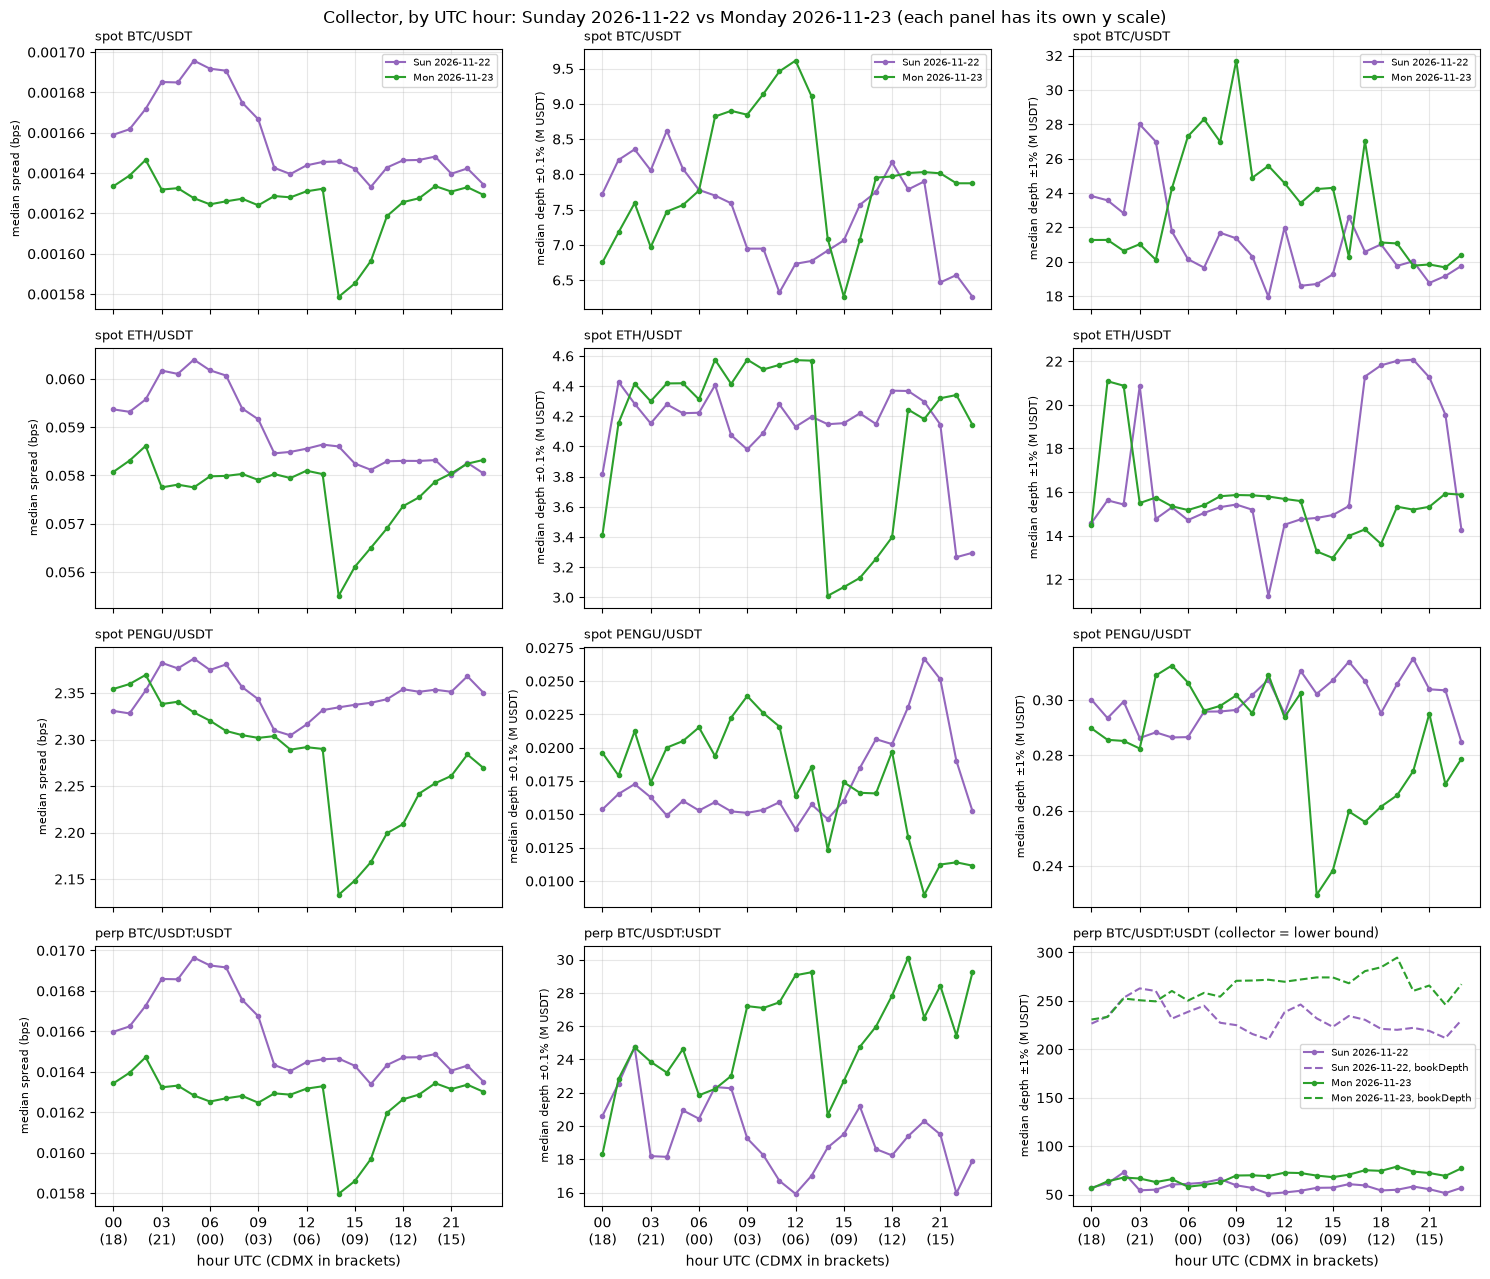

In [17]:
bd_run_hourly = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["1pct_total"]])
bd_run_hourly = add_time_labels(bd_run_hourly.reset_index(), "timestamp_utc")
bd_run_hourly = bd_run_hourly[bd_run_hourly["date_utc"].isin(list(RUN_DAYS))]
bd_run_hourly["day"] = bd_run_hourly["date_utc"].map(RUN_DAYS)

fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True)
panels = [("spread med (bps)", "median spread (bps)"), ("±0.1% total med", "median depth ±0.1% (M USDT)"),
          ("±1% total med", "median depth ±1% (M USDT)")]
colors = {DAYS[0]: "tab:purple", DAYS[1]: "tab:green"}
for row, market in enumerate(MARKETS):
    for col, (stat, ylabel) in enumerate(panels):
        ax = axes[row, col]
        for day in DAYS:
            s = hourly_run.loc[(market, day), stat]
            ax.plot(s.index, s.values, marker=".", color=colors[day], label=day)
            if market == PERP and stat == "±1% total med":
                b = bd_run_hourly[bd_run_hourly["day"] == day].set_index("hour_utc")["1pct_total"] / USDT_M
                ax.plot(b.index, b.values, ls="--", color=colors[day], label=f"{day}, bookDepth")
        ax.set_title(f"{market}" + (" (collector = lower bound)" if market == PERP and col == 2 else ""),
                     fontsize=9, loc="left")
        ax.set_ylabel(ylabel, fontsize=8)
        ax.grid(alpha=0.3)
        if row == 0 or (market == PERP and col == 2):
            ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 3)])
    ax.set_xlabel("hour UTC (CDMX in brackets)")
fig.suptitle("Collector, by UTC hour: Sunday 2026-11-22 vs Monday 2026-11-23 (each panel has its own y scale)")
fig.tight_layout()
plt.show()

How to read it: one row of panels per market, one column per measure: median spread (bps),
median depth within ±0.1% and within ±1% (both sides, M USDT). x = UTC hour (CDMX below it, in
brackets); purple = Sunday, green = Monday. Each panel has its own y scale, so compare shapes
within a panel and levels with the tables. In the perp's ±1% panel the solid lines are the
collector's lower bound and the dashed lines bookDepth's ±1% for the same hours (complete, as
validated in Part 1).

### 4.1 Round-trip cost by hour (taker → taker)

Same code and fees as notebook 07 (`market_order_legs` + `round_trips`): buy at market, sell at
market on the same snapshot, same notional per leg. Sizes: 10k / 100k / 1M USDT (BTC spot, ETH
spot, BTC perp) and 1k / 10k / 100k (PENGU). The cost is split into **fee** (fixed: 20 bps spot,
10 bps perp) and **spread + impact** (what the book costs). Median across the snapshots of each
hour.

In [18]:
rt_run = rt[rt["date_utc"].isin(list(RUN_DAYS))].copy()
rt_run["day"] = rt_run["date_utc"].map(RUN_DAYS)
rt_run["book_bps"] = rt_run["spread_bps"] + rt_run["impact_bps"]
fill = rt_run.groupby(["market", "size_usdt"])["status"].apply(lambda s: f"{(s == STATUS_FILLED).sum()}/{len(s)}")
print("fillable snapshots per market and size:", fill.to_dict())
rt_hourly = rt_run.groupby(["market", "size_usdt", "day", "hour_utc"]).agg(
    total=("total_bps", "median"), fee=("fee_bps", "median"), book=("book_bps", "median"))


def cost_table(market):
    t = rt_hourly.loc[market][["total", "book"]].unstack(["size_usdt", "day"])
    t.columns = pd.MultiIndex.from_tuples([(f"{s:,.0f}", d, "total" if c == "total" else "spread+impact")
                                           for c, s, d in t.columns])
    t = t.sort_index(axis=1, level=[0, 1], sort_remaining=False)
    t = t[[c for s in dict.fromkeys(c[0] for c in t.columns) for d in DAYS
           for c in [(s, d, "total"), (s, d, "spread+impact")]]]
    t.index = [hour_label(h) for h in t.index]
    t.index.name = "hour"
    return t


for market in MARKETS:
    fee = rt_hourly.loc[market, "fee"].iloc[0]
    print(f"{market} · taker -> taker median by hour, bps of the notional · fee = {fee:.0f} bps at every hour")
    display(cost_table(market).round(3))

fillable snapshots per market and size: {('perp BTC/USDT:USDT', 10000.0): '2880/2880', ('perp BTC/USDT:USDT', 100000.0): '2880/2880', ('perp BTC/USDT:USDT', 1000000.0): '2880/2880', ('spot BTC/USDT', 10000.0): '2880/2880', ('spot BTC/USDT', 100000.0): '2880/2880', ('spot BTC/USDT', 1000000.0): '2880/2880', ('spot ETH/USDT', 10000.0): '2880/2880', ('spot ETH/USDT', 100000.0): '2880/2880', ('spot ETH/USDT', 1000000.0): '2880/2880', ('spot PENGU/USDT', 1000.0): '2880/2880', ('spot PENGU/USDT', 10000.0): '2880/2880', ('spot PENGU/USDT', 100000.0): '2880/2880'}
spot BTC/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000,000                                                    10,000                                                   100,000                \
                 Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22                 
                          total spread+impact          total spread+impact          total spread+impact          total spread+impact          total spread+impact   
hour                                                                                                                                                                
00 UTC (18 CDMX)         22.321         2.321         23.250         3.250         20.002         0.002         20.002         0.002         20.141         0.141   
01 UTC (19 CDMX)         22.200         2.200         23.025         3.025         20.002         0.002         20.002         0.002         20.166         0.166   
02 UTC (20 CDMX)         22.402         2.402         22.761         2.761         20.002         0.002         20.002         0.002         20.354         0.354   
03 UTC (21 CDMX)         22.695         2.695         23.430         3.430         20.002         0.002         20.002         0.002         20.482         0.482   
04 UTC (22 CDMX)         22.509         2.509         22.905         2.905         20.002         0.002         20.002         0.002         20.531         0.531   
05 UTC (23 CDMX)         22.600         2.600         22.773         2.773         20.002         0.002         20.002         0.002         20.406         0.406   
06 UTC (00 CDMX)         22.645         2.645         22.615         2.615         20.002         0.002         20.002         0.002         20.361         0.361   
07 UTC (01 CDMX)         22.566         2.566         22.355         2.355         20.002         0.002         20.002         0.002         20.273         0.273   
08 UTC (02 CDMX)         23.055         3.055         22.389         2.389         20.002         0.002         20.002         0.002         20.618         0.618   
09 UTC (03 CDMX)         23.264         3.264         22.556         2.556         20.002         0.002         20.002         0.002         20.816         0.816   
10 UTC (04 CDMX)         23.022         3.022         22.282         2.282         20.002         0.002         20.002         0.002         20.494         0.494   
11 UTC (05 CDMX)         23.377         3.377         21.924         1.924         20.002         0.002         20.002         0.002         20.806         0.806   
12 UTC (06 CDMX)         23.310         3.310         22.091         2.091         20.002         0.002         20.002         0.002         20.810         0.810   
13 UTC (07 CDMX)         23.211         3.211         22.616         2.616         20.002         0.002         20.002         0.002         20.659         0.659   
14 UTC (08 CDMX)         22.883         2.883         23.505         3.505         20.002         0.002         20.002         0.002         20.443         0.443   
15 UTC (09 CDMX)         22.960         2.960         24.100         4.100         20.002         0.002         20.002         0.002         20.551         0.551   
16 UTC (10 CDMX)         22.798         2.798         23.588         3.588         20.002         0.002         20.002         0.002         20.471         0.471   
17 UTC (11 CDMX)         22.773         2.773         22.780         2.780         20.002         0.002         20.002         0.002         20.424         0.424   
18 UTC (12 CDMX)         22.665         2.665         22.623         2.623         20.002         0.002         20.002         0.002         20.453         0.453   
19 UTC (13 CDMX)         22.395         2.395         22.697         2.697         20.002         0.002         20.002         0.002         20.299         0.299   
20 UTC (14 CDMX)         22.388         2.388         22.630  

spot ETH/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000,000                                                    10,000                                                   100,000                \
                 Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22                 
                          total spread+impact          total spread+impact          total spread+impact          total spread+impact          total spread+impact   
hour                                                                                                                                                                
00 UTC (18 CDMX)         25.402         5.402         26.127         6.127         20.059         0.059         20.082         0.082         20.910         0.910   
01 UTC (19 CDMX)         25.169         5.169         25.611         5.611         20.059         0.059         20.058         0.058         20.787         0.787   
02 UTC (20 CDMX)         25.629         5.629         25.530         5.530         20.060         0.060         20.059         0.059         21.099         1.099   
03 UTC (21 CDMX)         25.826         5.826         25.672         5.672         20.060         0.060         20.236         0.236         21.320         1.320   
04 UTC (22 CDMX)         25.652         5.652         25.299         5.299         20.060         0.060         20.058         0.058         21.129         1.129   
05 UTC (23 CDMX)         25.739         5.739         25.303         5.303         20.090         0.090         20.058         0.058         21.352         1.352   
06 UTC (00 CDMX)         25.710         5.710         25.201         5.201         20.064         0.064         20.058         0.058         21.252         1.252   
07 UTC (01 CDMX)         25.591         5.591         24.967         4.967         20.060         0.060         20.058         0.058         21.027         1.027   
08 UTC (02 CDMX)         25.929         5.929         25.034         5.034         20.060         0.060         20.058         0.058         21.361         1.361   
09 UTC (03 CDMX)         26.110         6.110         25.013         5.013         20.059         0.059         20.058         0.058         21.374         1.374   
10 UTC (04 CDMX)         25.815         5.815         24.929         4.929         20.058         0.058         20.058         0.058         21.018         1.018   
11 UTC (05 CDMX)         25.552         5.552         24.746         4.746         20.059         0.059         20.058         0.058         21.186         1.186   
12 UTC (06 CDMX)         25.721         5.721         24.920         4.920         20.061         0.061         20.058         0.058         21.434         1.434   
13 UTC (07 CDMX)         25.692         5.692         25.202         5.202         20.059         0.059         20.058         0.058         21.160         1.160   
14 UTC (08 CDMX)         25.545         5.545         27.647         7.647         20.059         0.059         20.056         0.056         21.132         1.132   
15 UTC (09 CDMX)         25.571         5.571         27.206         7.206         20.058         0.058         20.057         0.057         21.179         1.179   
16 UTC (10 CDMX)         25.379         5.379         27.094         7.094         20.058         0.058         20.057         0.057         21.124         1.124   
17 UTC (11 CDMX)         25.537         5.537         26.731         6.731         20.058         0.058         20.057         0.057         20.964         0.964   
18 UTC (12 CDMX)         25.216         5.216         26.340         6.340         20.058         0.058         20.057         0.057         20.970         0.970   
19 UTC (13 CDMX)         24.985         4.985         25.420         5.420         20.058         0.058         20.058         0.058         20.659         0.659   
20 UTC (14 CDMX)         24.949         4.949         25.189  

spot PENGU/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000                                                    10,000                                                   100,000                \
                 Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22                 
                          total spread+impact          total spread+impact          total spread+impact          total spread+impact          total spread+impact   
hour                                                                                                                                                                
00 UTC (18 CDMX)         27.970         7.970         25.936         5.936         35.670        15.670         33.767        13.767         74.540        54.540   
01 UTC (19 CDMX)         26.429         6.429         25.914         5.914         34.503        14.503         33.814        13.814         73.234        53.234   
02 UTC (20 CDMX)         27.474         7.474         26.328         6.328         35.219        15.219         33.471        13.471         76.072        56.072   
03 UTC (21 CDMX)         27.657         7.657         26.165         6.165         35.688        15.688         34.353        14.353         78.587        58.587   
04 UTC (22 CDMX)         28.072         8.072         26.267         6.267         35.921        15.921         34.069        14.069         79.394        59.394   
05 UTC (23 CDMX)         28.100         8.100         26.442         6.442         35.662        15.662         33.352        13.352         77.304        57.304   
06 UTC (00 CDMX)         27.841         7.841         25.439         5.439         35.694        15.694         32.650        12.650         75.898        55.898   
07 UTC (01 CDMX)         27.170         7.170         25.197         5.197         35.246        15.246         32.729        12.729         74.760        54.760   
08 UTC (02 CDMX)         26.878         6.878         25.580         5.580         35.668        15.668         32.679        12.679         78.729        58.729   
09 UTC (03 CDMX)         26.798         6.798         25.595         5.595         35.374        15.374         31.895        11.895         77.043        57.043   
10 UTC (04 CDMX)         27.016         7.016         25.570         5.570         35.179        15.179         31.673        11.673         76.397        56.397   
11 UTC (05 CDMX)         27.389         7.389         26.041         6.041         34.754        14.754         33.039        13.039         72.477        52.477   
12 UTC (06 CDMX)         27.239         7.239         25.744         5.744         35.663        15.663         34.180        14.180         78.564        58.564   
13 UTC (07 CDMX)         26.471         6.471         25.946         5.946         35.061        15.061         33.458        13.458         75.007        55.007   
14 UTC (08 CDMX)         26.815         6.815         27.275         7.275         35.496        15.496         38.108        18.108         77.262        57.262   
15 UTC (09 CDMX)         26.831         6.831         26.667         6.667         35.345        15.345         36.053        16.053         73.696        53.696   
16 UTC (10 CDMX)         26.568         6.568         27.230         7.230         34.621        14.621         36.056        16.056         72.171        52.171   
17 UTC (11 CDMX)         26.348         6.348         27.010         7.010         33.527        13.527         36.456        16.456         73.160        53.160   
18 UTC (12 CDMX)         26.737         6.737         27.855         7.855         33.611        13.611         35.448        15.448         72.297        52.297   
19 UTC (13 CDMX)         26.514         6.514         27.602         7.602         33.084        13.084         37.408        17.408         70.470        50.470   
20 UTC (14 CDMX)         26.237         6.237         28.558      

perp BTC/USDT:USDT · taker -> taker median by hour, bps of the notional · fee = 10 bps at every hour


1,000,000                                                    10,000                                                   100,000                \
                 Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22               Mon 2026-11-23               Sun 2026-11-22                 
                          total spread+impact          total spread+impact          total spread+impact          total spread+impact          total spread+impact   
hour                                                                                                                                                                
00 UTC (18 CDMX)         11.681         1.681         12.265         2.265         10.017         0.017         10.016         0.016         10.017         0.017   
01 UTC (19 CDMX)         11.448         1.448         11.851         1.851         10.017         0.017         10.016         0.016         10.017         0.017   
02 UTC (20 CDMX)         11.519         1.519         11.556         1.556         10.017         0.017         10.016         0.016         10.017         0.017   
03 UTC (21 CDMX)         11.959         1.959         11.799         1.799         10.017         0.017         10.016         0.016         10.017         0.017   
04 UTC (22 CDMX)         11.938         1.938         11.680         1.680         10.017         0.017         10.016         0.016         10.017         0.017   
05 UTC (23 CDMX)         11.759         1.759         11.628         1.628         10.017         0.017         10.016         0.016         10.017         0.017   
06 UTC (00 CDMX)         11.808         1.808         11.567         1.567         10.017         0.017         10.016         0.016         10.017         0.017   
07 UTC (01 CDMX)         11.825         1.825         11.614         1.614         10.017         0.017         10.016         0.016         10.017         0.017   
08 UTC (02 CDMX)         11.950         1.950         11.768         1.768         10.017         0.017         10.016         0.016         10.017         0.017   
09 UTC (03 CDMX)         12.006         2.006         11.602         1.602         10.017         0.017         10.016         0.016         10.024         0.024   
10 UTC (04 CDMX)         12.148         2.148         11.435         1.435         10.016         0.016         10.016         0.016         10.158         0.158   
11 UTC (05 CDMX)         12.033         2.033         11.558         1.558         10.016         0.016         10.016         0.016         10.040         0.040   
12 UTC (06 CDMX)         12.463         2.463         11.563         1.563         10.016         0.016         10.016         0.016         10.170         0.170   
13 UTC (07 CDMX)         12.531         2.531         11.635         1.635         10.016         0.016         10.016         0.016         10.138         0.138   
14 UTC (08 CDMX)         12.152         2.152         12.500         2.500         10.016         0.016         10.016         0.016         10.034         0.034   
15 UTC (09 CDMX)         12.025         2.025         12.123         2.123         10.016         0.016         10.016         0.016         10.096         0.096   
16 UTC (10 CDMX)         12.037         2.037         11.945         1.945         10.016         0.016         10.016         0.016         10.078         0.078   
17 UTC (11 CDMX)         12.234         2.234         11.732         1.732         10.016         0.016         10.016         0.016         10.091         0.091   
18 UTC (12 CDMX)         12.210         2.210         11.562         1.562         10.016         0.016         10.016         0.016         10.104         0.104   
19 UTC (13 CDMX)         12.305         2.305         11.419         1.419         10.016         0.016         10.016         0.016         10.092         0.092   
20 UTC (14 CDMX)         12.098         2.098         11.720  

How to read it: the first line counts the snapshots where the visible book could fill both legs
(all of them if every entry reads n/n). Then one table per market: one row per UTC hour; for
each size (USDT per leg) and day, `total` is the median round-trip cost in **bps of the notional**
(20 = 0.20% of the position, paid once to get in and out) and `spread+impact` is the part paid
to the book. The fee is the same at every hour and is printed above each table, so `total` −
`spread+impact` ≈ fee (exactly, since the fee is a constant).

In [19]:
rows = []
for (market, size), g in rt_hourly.groupby(level=["market", "size_usdt"]):
    g = g.droplevel(["market", "size_usdt"])
    lo, hi = g["book"].idxmin(), g["book"].idxmax()
    rows.append({"market": market, "size (USDT)": f"{size:,.0f}", "fee (bps)": g["fee"].iloc[0],
                 "spread+impact: lowest hourly median (bps)": g["book"].min(),
                 "at": f"{lo[0][:3]} {hour_label(lo[1])}",
                 "spread+impact: highest hourly median (bps)": g["book"].max(),
                 "at ": f"{hi[0][:3]} {hour_label(hi[1])}",
                 "highest / lowest": g["book"].max() / g["book"].min(),
                 "fee share of total at the worst hour (%)": 100 * g["fee"].iloc[0] / g.loc[hi, "total"]})
cost_range = pd.DataFrame(rows).set_index(["market", "size (USDT)"]).reindex(MARKETS, level=0)
cost_range.round(3)

fee (bps)  spread+impact: lowest hourly median (bps)                    at  spread+impact: highest hourly median (bps)  \
market             size (USDT)                                                                                                                           
spot BTC/USDT      10,000            20.0                                      0.002  Mon 14 UTC (08 CDMX)                                       0.002   
                   100,000           20.0                                      0.033  Mon 11 UTC (05 CDMX)                                       0.986   
                   1,000,000         20.0                                      1.924  Mon 11 UTC (05 CDMX)                                       4.100   
spot ETH/USDT      10,000            20.0                                      0.056  Mon 14 UTC (08 CDMX)                                       0.236   
                   100,000           20.0                                      0.573  Mon 11 UTC (05 CDMX)                                       1.454   
                   1,000,000         20.0                                      4.746  Mon 11 UTC (05 CDMX)                                       7.647   
spot PENGU/USDT    1,000             20.0                                      5.197  Mon 07 UTC (01 CDMX)                                       9.298   
                   10,000            20.0                                     11.673  Mon 10 UTC (04 CDMX)                                      18.621   
                   100,000           20.0                                     49.822  Sun 21 UTC (15 CDMX)                                      84.829   
perp BTC/USDT:USDT 10,000            10.0                                      0.016  Mon 14 UTC (08 CDMX)                                       0.017   
                   100,000           10.0                                      0.016  Mon 16 UTC (10 CDMX)                                       0.218   
                   1,000,000         10.0                                      1.419  Mon 19 UTC (13 CDMX)                                       2.553   

                                                 at   highest / lowest  fee share of total at the worst hour (%)  
market             size (USDT)                                                                                    
spot BTC/USDT      10,000       Sun 05 UTC (23 CDMX)             1.070                                    99.992  
                   100,000      Mon 14 UTC (08 CDMX)            30.156                                    95.301  
                   1,000,000    Mon 15 UTC (09 CDMX)             2.130                                    82.988  
spot ETH/USDT      10,000       Mon 03 UTC (21 CDMX)             4.214                                    98.831  
                   100,000      Mon 15 UTC (09 CDMX)             2.537                                    93.223  
                   1,000,000    Mon 14 UTC (08 CDMX)             1.611                                    72.340  
spot PENGU/USDT    1,000        Mon 22 UTC (16 CDMX)             1.789                                    68.265  
                   10,000       Mon 20 UTC (14 CDMX)             1.595                                    51.786  
                   100,000      Mon 14 UTC (08 CDMX)             1.703                                    19.079  
perp BTC/USDT:USDT 10,000       Sun 05 UTC (23 CDMX)             1.072                                    99.831  
                   100,000      Mon 14 UTC (08 CDMX)            13.519                                    97.870  
                   1,000,000    Sun 22 UTC (16 CDMX)             1.800                                    79.661

How to read it: one row per market and size, summarizing the 48 hourly medians of the previous
tables. The lowest and highest hourly median of the **book part** (spread + impact, bps) and the
day and hour where each happened; their ratio (how many times more expensive the book was at its
worst hour than at its best); and the share of the fee in the total at that worst hour (close to
100% = the hour barely matters next to the fee).

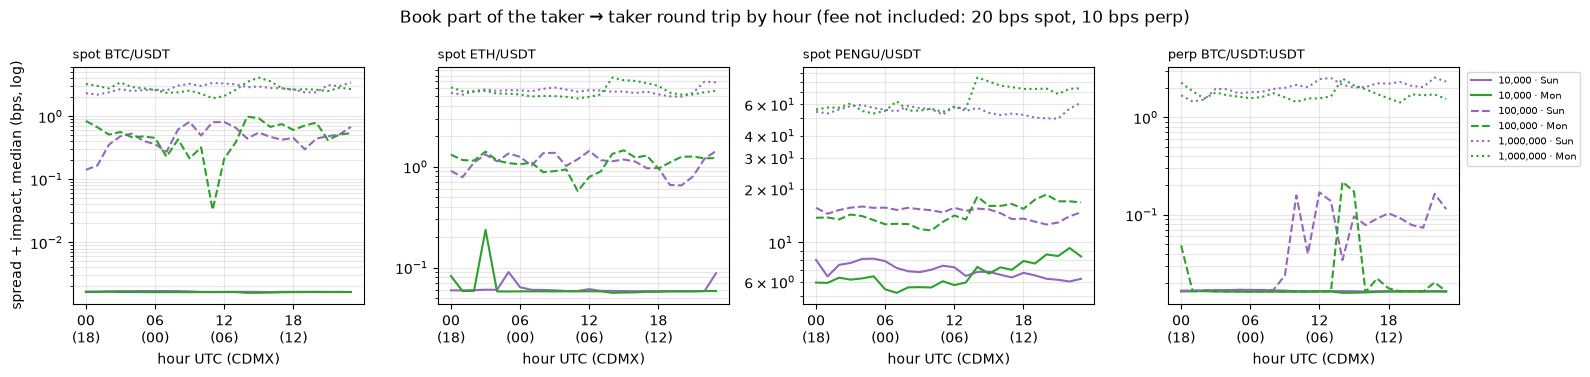

In [20]:
fig, axes = plt.subplots(1, len(MARKETS), figsize=(16, 3.8))
for ax, market in zip(axes, MARKETS):
    for size, ls in zip(SIZES[market], ["-", "--", ":"]):
        for day in DAYS:
            s = rt_hourly.loc[(market, size, day), "book"]
            ax.plot(s.index, s.values, ls=ls, color=colors[day], label=f"{size:,.0f} · {day[:3]}")
    ax.set_yscale("log")
    ax.set_title(market, fontsize=9, loc="left")
    ax.set_xticks(range(0, 24, 6))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 6)])
    ax.set_xlabel("hour UTC (CDMX)")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("spread + impact, median (bps, log)")
axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Book part of the taker → taker round trip by hour (fee not included: 20 bps spot, 10 bps perp)")
fig.tight_layout()
plt.show()

How to read it: one panel per market; x = UTC hour (CDMX), y = median spread + impact of the
round trip in bps on a **log scale** (each grid step ×10). Line style = size (solid smallest,
dotted largest), color = day (purple Sunday, green Monday). The fee is left out on purpose: add
20 bps (spot) or 10 bps (perp) to read the total. Flat lines = the hour does not matter for that
size; bumps = hours when the book was thinner or the spread wider.

### 4.2 Spot vs perp: do their depth profiles move together?

Correlation between the 48 hourly medians (Sunday + Monday) of spot depth and perp depth.
±0.1% and ±0.2% use the collector on both sides (both complete); ±1% uses spot from the collector
and the perp from bookDepth (*post-inspection*: the collector's perp ±1% is only a lower bound).

perp source  hours  Pearson corr  rank corr
spot market     band                                            
spot BTC/USDT   0.1%   collector     48         0.608      0.561
                0.2%   collector     48         0.474      0.458
                1%     bookDepth     48         0.505      0.542
spot ETH/USDT   0.1%   collector     48         0.225      0.381
                0.2%   collector     48         0.098      0.216
                1%     bookDepth     48        -0.326     -0.176
spot PENGU/USDT 0.1%   collector     48        -0.073      0.065
                0.2%   collector     48        -0.398     -0.356
                1%     bookDepth     48        -0.545     -0.480

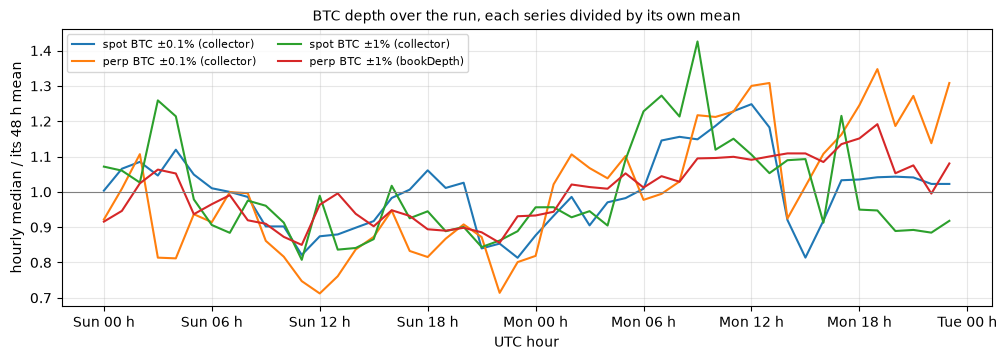

In [21]:
hourly_key = run.assign(hour=run["local_receive_utc"].dt.floor("1h"))
prof = hourly_key.groupby(["market", "hour"])[["depth_0.1pct_total_usdt", "depth_0.2pct_total_usdt",
                                                "depth_1pct_total_usdt"]].median()
bd_1pct = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["1pct_total"]])["1pct_total"]
rows = []
for spot in (BTC_SPOT, ETH_SPOT, PENGU):
    for band in ("0.1pct", "0.2pct", "1pct"):
        x = prof.loc[spot, f"depth_{band}_total_usdt"]
        y = bd_1pct.reindex(x.index) if band == "1pct" else prof.loc[PERP, f"depth_{band}_total_usdt"]
        both = pd.concat([x, y], axis=1, keys=["spot", "perp"]).dropna()
        rows.append({"spot market": spot, "band": band.replace("pct", "%"),
                     "perp source": "bookDepth" if band == "1pct" else "collector",
                     "hours": len(both), "Pearson corr": both["spot"].corr(both["perp"]),
                     "rank corr": both["spot"].rank().corr(both["perp"].rank())})
spot_perp = pd.DataFrame(rows).set_index(["spot market", "band"])
display(spot_perp.round(3))

fig, ax = plt.subplots(figsize=(12, 3.6))
for name, s in (("spot BTC ±0.1% (collector)", prof.loc[BTC_SPOT, "depth_0.1pct_total_usdt"]),
                ("perp BTC ±0.1% (collector)", prof.loc[PERP, "depth_0.1pct_total_usdt"]),
                ("spot BTC ±1% (collector)", prof.loc[BTC_SPOT, "depth_1pct_total_usdt"]),
                ("perp BTC ±1% (bookDepth)", bd_1pct.reindex(prof.loc[BTC_SPOT].index))):
    ax.plot(s.index, s / s.mean(), label=name)
ax.axhline(1, color="grey", lw=0.8)
ax.set_ylabel("hourly median / its 48 h mean")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %H h", tz="UTC"))
ax.set_xlabel("UTC hour")
ax.set_title("BTC depth over the run, each series divided by its own mean", fontsize=10)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.show()

How to read it: the table has one row per spot market and band; `hours` = hourly points paired
(48 if both full days are there); `Pearson corr` = linear correlation of the two hourly series
(+1 = they rise and fall together in proportion, 0 = no linear relation, −1 = opposite);
`rank corr` = the same on ranks (less sensitive to one extreme hour). With 48 points, a
correlation of about ±0.28 or more is unlikely to come from pure chance if the hours were
independent; hourly depth is not independent from one hour to the next, so that threshold is
optimistic. The plot divides each BTC series by its own mean so books of different size share
one axis: 1.2 = 20% more depth than that book's average over the run.

## 5. Part 3 · Perp BTCUSDT over 12 months (bookDepth, 2025-11-24 → 2026-11-23)

Per bookDepth timestamp (~30 s): cumulative USDT depth within ±0.2% and ±1% of the mid, per side
and total. Each hour is summarized by the **median of its ~120 timestamps**; the patterns below
are statistics of those hourly values across days.

Periods kept apart (lab rule 4, fixed before looking): **post-hack, 2026-10-29 → 2026-11-14**
(labeled, shown on its own, excluded from every "normal" pattern), and the **10 October 2025**
stress case (2025-10-06 → 2025-10-14, outside the window).

In [22]:
bd_days = sorted({d.strftime("%Y-%m-%d") for d in pd.date_range(*WINDOW_12M, freq="D")}
                 | {d.strftime("%Y-%m-%d") for d in pd.date_range(*STRESS_10_10, freq="D")})
sides_path, quality_path = CACHE / "bookdepth_sides_30s.parquet", CACHE / "bookdepth_quality.parquet"
if not (sides_path.exists() and quality_path.exists()):
    frames, quality = [], []
    for day in bd_days:
        if not (VISION / book_depth_path("BTCUSDT", day)).exists():   # not published by Binance
            continue
        raw = read_book_depth_day(day)
        w = book_depth_wide(raw)
        ts = w.index.to_series()
        quality.append({"day": pd.Timestamp(day, tz="UTC"), "rows": len(raw), "timestamps": len(w),
                        "percentages": len(w["notional"].columns),
                        "has ±0.2": all(p in w["notional"].columns for p in (-0.2, 0.2)),
                        "has ±1": all(p in w["notional"].columns for p in (-1.0, 1.0)),
                        "max step (s)": ts.diff().dt.total_seconds().max(),
                        "first": ts.iloc[0], "last": ts.iloc[-1],
                        "cumulative (% complete rows)": check_cumulative(w.dropna())["monotonic (% of timestamps)"].min()})
        frames.append(book_depth_side_totals(w, pcts=(0.2, 1.0)))
    pd.concat(frames).to_parquet(sides_path)
    pd.DataFrame(quality).to_parquet(quality_path)
bd_sides = pd.read_parquet(sides_path)
bd_quality = pd.read_parquet(quality_path).set_index("day")
not_published = sorted(set(bd_days) - {d.strftime("%Y-%m-%d") for d in bd_quality.index})
print(f"{len(bd_quality)} daily files of {len(bd_days)} days asked, {len(bd_sides):,} timestamps; "
      f"not published on data.binance.vision (left out, not filled): {not_published}")
print(f"timestamps per day: min {bd_quality['timestamps'].min()}, median {bd_quality['timestamps'].median():.0f}, "
      f"max {bd_quality['timestamps'].max()}; every day has ±1%: {bool(bd_quality['has ±1'].all())}; "
      f"cumulative on every complete row of every day: {bool((bd_quality['cumulative (% complete rows)'] == 100).all())}")
short = bd_quality[bd_quality["timestamps"] < 2400]
print(f"days with fewer than 2,400 timestamps (of 2,880): {[f'{d:%Y-%m-%d} ({n})' for d, n in short['timestamps'].items()]}")
with_02 = bd_quality[bd_quality["has ±0.2"]]
print(f"days with ±0.2%: {len(with_02)} of {len(bd_quality)}; first {with_02.index.min():%Y-%m-%d}, last "
      f"{with_02.index.max():%Y-%m-%d}; days without it: {int((~bd_quality['has ±0.2']).sum())} "
      f"(first {bd_quality.index[~bd_quality['has ±0.2']].min():%Y-%m-%d}, last "
      f"{bd_quality.index[~bd_quality['has ±0.2']].max():%Y-%m-%d})")
holes = bd_quality[bd_quality["max step (s)"] > 120]
print(f"days with a hole longer than 2 min between timestamps: {len(holes)}")
holes[["timestamps", "max step (s)", "first", "last"]]

373 daily files of 374 days asked, 1,036,432 timestamps; not published on data.binance.vision (left out, not filled): ['2026-10-08']
timestamps per day: min 339, median 2821, max 2880; every day has ±1%: True; cumulative on every complete row of every day: True
days with fewer than 2,400 timestamps (of 2,880): ['2026-10-07 (339)', '2026-10-09 (2389)']
days with ±0.2%: 312 of 373; first 2026-01-15, last 2026-11-23; days without it: 61 (first 2025-10-06, last 2026-01-14)
days with a hole longer than 2 min between timestamps: 194


,timestamps,max step (s),first,last
day,,,,
2025-10-08 00:00:00+00:00,2863,177.0,2025-10-08 00:00:07+00:00,2025-10-08 23:59:31+00:00
2025-10-09 00:00:00+00:00,2821,1408.0,2025-10-09 00:00:07+00:00,2025-10-09 23:59:31+00:00
2025-10-11 00:00:00+00:00,2845,181.0,2025-10-11 00:00:07+00:00,2025-10-11 23:59:31+00:00
2025-10-12 00:00:00+00:00,2812,210.0,2025-10-12 00:00:07+00:00,2025-10-12 23:59:30+00:00
2025-10-13 00:00:00+00:00,2812,210.0,2025-10-13 00:00:07+00:00,2025-10-13 23:59:31+00:00
...,...,...,...,...
2026-05-30 00:00:00+00:00,2674,243.0,2026-05-30 00:00:08+00:00,2026-05-30 23:59:32+00:00
2026-05-31 00:00:00+00:00,2592,233.0,2026-05-31 00:00:07+00:00,2026-05-31 23:59:31+00:00
2026-06-01 00:00:00+00:00,2628,240.0,2026-06-01 00:00:07+00:00,2026-06-01 23:59:30+00:00


How to read it: the lines summarize the quality of every daily file: how many there are, the
number of timestamps per day (2,880 = one every 30 s for 24 h), whether every day has ±1%, which
days have ±0.2%, whether the cumulative property of Part 1 holds on every row that has all its
percentages (on the first day with ±0.2% those rows start during the day, so its earlier rows are
incomplete), and which days have far fewer timestamps than 2,880 (a short file: its hours rest on
fewer values). The table lists the days where Binance's file has a gap of more than 2 minutes
between consecutive timestamps (empty = none): those hours have fewer timestamps behind their
median, nothing is filled in.

*Post-inspection:* the older BTCUSDT files **have no ±0.2% rows** (10 percentages, ±1 … ±5); the
first day with ±0.2% is printed above. Nothing is filled in: every ±0.2% number in this
part covers only the days that have it (fewer weeks per cell, fewer window months), while ±1%
covers the full 12 months. ±1% is therefore the main series for H1, H5 and H6; ±0.2% is shown as
a second, shorter check. The 10/10 case (2025) has no ±0.2%.

### 5.1 Frozen and broken values (post-inspection)

Looking at the series showed values that a real book cannot produce: one side stuck at the same
value (or two values taking turns) for hours or days, and stretches where one side sits near zero
while the other is several times its usual size (as if the file measured both sides from a wrong
mid). On the three days validated in Part 1 no value ever repeats exactly (a cumulative USDT sum
with many decimals), so an exact repeat is a strong sign of a frozen file. The tables below show
where it happens.

**Rules (post-inspection; nothing is filled in):**

1. A side's value that appears **exactly ≥ 20 times in the same UTC day** (~10 minutes of rows)
   is set to NaN, and so is the total. Counting per day catches values that alternate or come
   back between other rows. The share flagged was checked to barely depend on the threshold
   (5 to 40 repeats).
2. A day where **any** column has **more than 5%** of its values flagged is **dropped from every
   12-month pattern**: on such days the other side looked distorted too. The 10/10 case keeps
   its days (it is shown on its own), with the frozen values removed.

Section 5.2 repeats the key numbers on the raw series, to show whether the rule matters.

In [23]:
bd_clean, frozen, frozen_day_share, BAD_DAYS = clean_book_depth(bd_sides, min_count=20, max_day_share=0.05)
in_window_rows = bd_sides.index >= pd.Timestamp(WINDOW_12M[0], tz="UTC")
has_value = bd_sides[frozen.columns].notna()
flagged = frozen & has_value


def share(rows):
    return flagged[rows].sum() / has_value[rows].sum() * 100


validation_rows = bd_sides.index.floor("D").isin(pd.to_datetime([DAY_06, "2026-11-22", "2026-11-23"], utc=True))
frozen_share = pd.DataFrame({"10/10 case": share(~in_window_rows), "12-month window": share(in_window_rows),
                             "Part 1 validation days": share(validation_rows)}).T
print("share of rows with a value that are flagged as frozen (%)")
display(frozen_share.round(2))
print(f"days dropped from the 12-month patterns (> 5% frozen in some column): "
      f"{[f'{d:%Y-%m-%d}' for d in BAD_DAYS if d >= pd.Timestamp(WINDOW_12M[0], tz='UTC')]}")
frozen_day_share[(frozen_day_share > 0).any(axis=1)].mul(100).round(1)

share of rows with a value that are flagged as frozen (%)


,0.2pct_bid,0.2pct_ask,1pct_bid,1pct_ask
10/10 case,NaN,NaN,47.79,0.0
12-month window,0.31,2.28,0.07,1.2
Part 1 validation days,0.00,0.00,0.00,0.0


days dropped from the 12-month patterns (> 5% frozen in some column): ['2026-03-20', '2026-04-22', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11']


,0.2pct_bid,0.2pct_ask,1pct_bid,1pct_ask
timestamp_utc,,,,
2025-10-10 00:00:00+00:00,NaN,NaN,33.1,0.0
2025-10-11 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-12 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-13 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-14 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-12-01 00:00:00+00:00,NaN,NaN,4.7,4.7
2026-03-20 00:00:00+00:00,11.2,11.2,11.2,11.2
2026-04-22 00:00:00+00:00,11.0,11.0,11.0,11.0
2026-09-03 00:00:00+00:00,0.0,46.7,0.0,39.9


How to read it: first table, the share (%) of bookDepth rows **that have a value** flagged as
frozen, per side and band (columns), in the 10/10 case, in the 12-month window and on the three
days used in Part 1 (±0.2% only counts the days that have it). Then the list of days
dropped from the 12-month patterns. The last table shows every day with at least one frozen
value: the % of that day's values flagged in each column. A day at 100% in one column had that
side frozen all day.

In [24]:
bd_h = resample_hourly(bd_clean)
bd_h = add_time_labels(bd_h.reset_index().rename(columns={"timestamp_utc": "hour_start_utc"}), "hour_start_utc")
in_12m = bd_h["date_utc"].between(pd.Timestamp(WINDOW_12M[0], tz="UTC"), pd.Timestamp(WINDOW_12M[1], tz="UTC"))
is_hack = bd_h["date_utc"].between(*POST_HACK)
is_bad = bd_h["date_utc"].isin(BAD_DAYS)
bd_h["period"] = np.select([~in_12m, is_hack, is_bad], ["10/10 case", "post-hack", "broken file day"],
                           default="normal")
bd_h["month"] = window_month(bd_h["date_utc"])
DEPTH_COLS = ["0.2pct_bid", "0.2pct_ask", "0.2pct_total", "1pct_bid", "1pct_ask", "1pct_total"]
bd_h[DEPTH_COLS] = bd_h[DEPTH_COLS] / USDT_M                       # M USDT
normal = bd_h[bd_h["period"] == "normal"]
print(bd_h.groupby("period").agg(hours=("n", "size"), first=("hour_start_utc", "min"),
                                 last=("hour_start_utc", "max"), median_rows_per_hour=("n", "median")))
print(f"normal hours per weekday x hour cell: min {normal.groupby(['weekday', 'hour_utc']).size().min()}, "
      f"max {normal.groupby(['weekday', 'hour_utc']).size().max()}")
normal[DEPTH_COLS].describe(percentiles=[0.1, 0.5, 0.9]).T.round(2)

                 hours                     first                      last  median_rows_per_hour
period                                                                                          
10/10 case         216 2025-10-06 00:00:00+00:00 2025-10-14 23:00:00+00:00                 120.0
broken file day    264 2026-03-20 00:00:00+00:00 2026-09-11 23:00:00+00:00                 120.0
normal            8039 2025-11-24 00:00:00+00:00 2026-11-23 23:00:00+00:00                 120.0
post-hack          408 2026-10-29 00:00:00+00:00 2026-11-14 23:00:00+00:00                 120.0
normal hours per weekday x hour cell: min 45, max 50


,count,mean,std,min,10%,50%,90%,max
0.2pct_bid,6784.0,38.53,20.86,12.31,24.43,35.87,52.53,325.78
0.2pct_ask,6784.0,37.77,14.44,12.78,24.28,36.09,52.70,276.36
0.2pct_total,6784.0,76.81,29.36,26.31,49.39,73.01,105.69,373.21
1pct_bid,8039.0,175.58,54.39,77.61,119.84,165.11,241.23,519.02
1pct_ask,8039.0,171.90,55.97,70.36,116.30,160.22,238.47,570.45
1pct_total,8039.0,349.01,85.73,149.66,248.71,340.15,459.34,794.60


How to read it: the first table counts the hourly values in each period (normal 12 months, the
post-hack weeks, the days dropped by rule 2 of section 5.1, the 10/10 case) with their first and last hour and the median number of
bookDepth timestamps behind each hourly value (~120). Then how many hours fall in each of the
168 weekday × hour cells (about 50: one per week). The last table describes the normal hourly
values in **millions of USDT**: per side and total, for ±0.2% and ±1%, with p10 / median / p90.

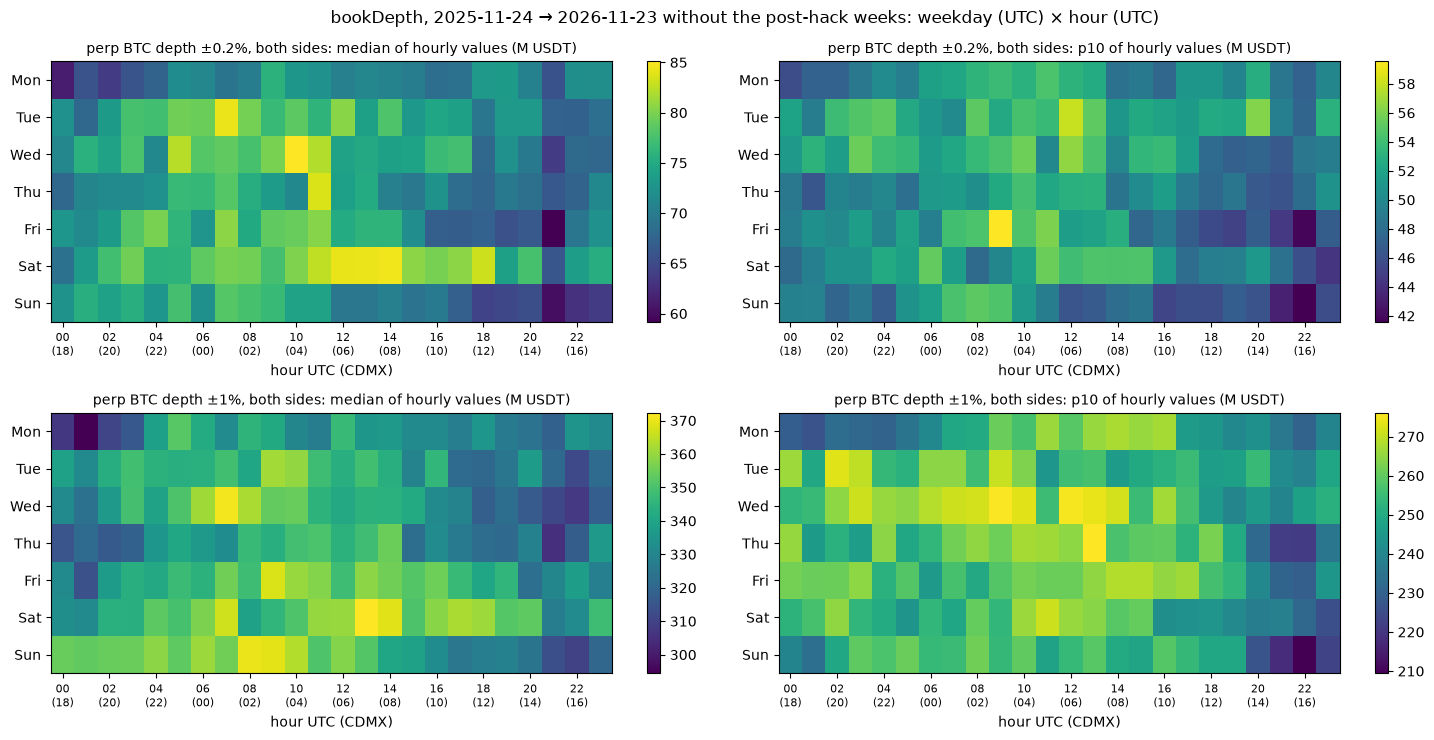

In [25]:
heat = {(col, stat): week_heatmap(normal, col, "median" if stat == "median" else quantile(0.1))
        for col in ("0.2pct_total", "1pct_total") for stat in ("median", "p10")}
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for ax, ((col, stat), table) in zip(axes.ravel(), heat.items()):
    im = ax.imshow(table.to_numpy(), aspect="auto", cmap="viridis")
    ax.set_yticks(range(7))
    ax.set_yticklabels(table.index)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 2)], fontsize=8)
    ax.set_xlabel("hour UTC (CDMX)")
    band = col.split("_")[0].replace("pct", "%")
    ax.set_title(f"perp BTC depth ±{band}, both sides: {stat} of hourly values (M USDT)", fontsize=10)
    fig.colorbar(im, ax=ax)
fig.suptitle("bookDepth, 2025-11-24 → 2026-11-23 without the post-hack weeks: weekday (UTC) × hour (UTC)")
fig.tight_layout()
plt.show()

How to read it: four heatmaps. Rows = UTC weekday (Mon at the top), columns = UTC hour (CDMX in
brackets), color = depth in millions of USDT within ±0.2% (top) or ±1% (bottom) of the mid, both
sides added. Left: the **median** hourly value of that cell across the ~50 weeks (a typical
hour); right: the **p10** (one hour in ten was thinner than this: a bad but normal hour). Each
heatmap has its own color scale (bar on the right); bright = deep book, dark = thin book.

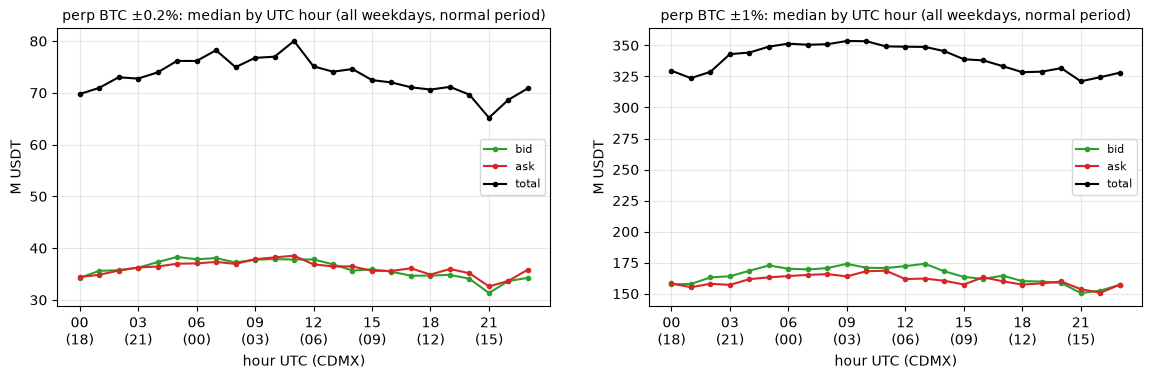

In [26]:
side_profile = normal.groupby("hour_utc")[DEPTH_COLS].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharex=True)
for ax, band in zip(axes, ("0.2pct", "1pct")):
    for part, color in (("bid", "tab:green"), ("ask", "tab:red"), ("total", "black")):
        ax.plot(side_profile.index, side_profile[f"{band}_{part}"], marker=".", color=color, label=part)
    ax.set_title(f"perp BTC ±{band.replace('pct', '%')}: median by UTC hour (all weekdays, normal period)", fontsize=10)
    ax.set_ylabel("M USDT")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 3)])
    ax.set_xlabel("hour UTC (CDMX)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.show()

How to read it: x = UTC hour (CDMX), y = median depth in millions of USDT over every normal day
at that hour; green = bids, red = asks, black = both. Left ±0.2%, right ±1%. If the two sides
move together across the day, the hour-of-day pattern is about how much is quoted overall, not
about one side.

In [27]:
heat_all = {c: week_heatmap(normal, c) for c in DEPTH_COLS}
ratios = pd.DataFrame({c: {"Tue 14 UTC (median, M USDT)": t.loc["Tue", 14],
                           "Sun 03 UTC (median, M USDT)": t.loc["Sun", 3],
                           "Tue 14 / Sun 03": t.loc["Tue", 14] / t.loc["Sun", 3],
                           "business 13-21 median (M USDT)": normal.loc[in_window(normal, **BUSINESS), c].median(),
                           "weekend 21-03 median (M USDT)": normal.loc[in_window(normal, **WEEKEND_NIGHT), c].median()}
                       for c, t in heat_all.items()}).T
ratios["business / weekend night"] = ratios["business 13-21 median (M USDT)"] / ratios["weekend 21-03 median (M USDT)"]
print(f"hours behind the general ratio: business {int(in_window(normal, **BUSINESS).sum())}, "
      f"weekend night {int(in_window(normal, **WEEKEND_NIGHT).sum())}")
ratios.round(3)

hours behind the general ratio: business 1904, weekend night 582


,"Tue 14 UTC (median, M USDT)","Sun 03 UTC (median, M USDT)",Tue 14 / Sun 03,business 13-21 median (M USDT),weekend 21-03 median (M USDT),business / weekend night
0.2pct_bid,37.290,36.351,1.026,35.261,33.589,1.050
0.2pct_ask,38.604,37.500,1.029,35.524,34.766,1.022
0.2pct_total,77.984,75.453,1.034,71.744,69.963,1.025
1pct_bid,165.986,167.960,0.988,162.561,158.469,1.026
1pct_ask,162.563,165.065,0.985,157.766,158.762,0.994
1pct_total,343.332,354.605,0.968,335.121,334.064,1.003


How to read it: one row per band and side. The first three columns compare two single cells of
the median heatmap, Tuesday 14 UTC (08 CDMX, Europe and the US both at work) and Sunday 03 UTC
(Saturday 21 CDMX, the quietest stretch of the week); the next three compare the two windows of
H1 (Mon–Fri 13:00–20:59 UTC vs Sat–Sun 21:00–02:59 UTC by UTC day), using the median over every
hour in each window. A ratio above 1 = more depth in the first one.

In [28]:
month_tables = {c: ratio_by_month(normal, c, month_col="month") for c in ("0.2pct_total", "1pct_total", "1pct_bid", "1pct_ask")}
by_month = pd.concat({c: t["ratio"] for c, t in month_tables.items()}, axis=1)
by_month.insert(0, "business hours", month_tables["1pct_total"]["numerator hours"])
by_month.insert(1, "weekend-night hours", month_tables["1pct_total"]["denominator hours"])
RATIO_COLS = ["0.2pct_total", "1pct_total", "1pct_bid", "1pct_ask"]
months_meeting = (by_month[RATIO_COLS] > 1).sum()
months_with_data = by_month[RATIO_COLS].notna().sum()
print("months with business / weekend-night ratio > 1:",
      {c: f"{months_meeting[c]} of {months_with_data[c]}" for c in RATIO_COLS})
by_month.round(3)

months with business / weekend-night ratio > 1: {'0.2pct_total': '8 of 11', '1pct_total': '8 of 12', '1pct_bid': '8 of 12', '1pct_ask': '5 of 12'}


,business hours,weekend-night hours,0.2pct_total,1pct_total,1pct_bid,1pct_ask
month,,,,,,
2025-11-24 to 2025-12-23,176,48,NaN,0.995,1.005,0.973
2025-12-24 to 2026-01-23,184,48,0.875,1.000,0.942,1.004
2026-01-24 to 2026-02-23,168,60,0.959,1.038,1.030,1.053
2026-02-24 to 2026-03-23,152,48,0.983,1.019,0.971,1.017
2026-03-24 to 2026-04-23,176,48,1.041,0.960,1.004,0.940
2026-04-24 to 2026-05-23,168,54,1.075,0.981,0.987,0.943
2026-05-24 to 2026-06-23,176,54,1.151,1.008,1.114,0.858
2026-06-24 to 2026-07-23,176,48,1.044,0.919,1.007,0.918
2026-07-24 to 2026-08-23,168,60,1.029,1.135,1.015,0.976


How to read it: one row per **window month** (24th to 23rd, so the 12 months fit exactly; the last
one is short because the post-hack days are left out; ±0.2% is NaN where the files lack it). The first two columns count the hourly
values behind the ratio; the rest are the ratio business 13–21 / weekend night 21–03 for ±0.2%
total, ±1% total and each side of ±1%. The printed line counts the months where the ratio is
above 1, i.e. where H1's pattern holds in that month.

In [29]:
pct_rows = {}
for c in ("0.2pct_total", "1pct_total"):
    t_med, t_p10 = heat[(c, "median")], heat[(c, "p10")]
    pct_rows[c] = {"Thu 22 UTC median (M USDT)": t_med.loc["Thu", 22],
                   "percentile among the 168 median cells": cell_percentile(t_med, "Thu", 22),
                   "percentile among the 168 p10 cells": cell_percentile(t_p10, "Thu", 22)}
win = bd_clean[(bd_clean.index >= pd.Timestamp(f"{DAY_06} 22:00", tz="UTC"))
               & (bd_clean.index < pd.Timestamp(f"{DAY_06} 22:45", tz="UTC"))] / USDT_M
thu22 = normal[(normal["weekday"] == 3) & (normal["hour_utc"] == 22)]
for c in ("0.2pct_total", "1pct_total"):
    v = win[c].median()
    pct_rows[c].update({"2026-11-19 22:00-22:45, median (M USDT)": v,
                        "timestamps in that window": len(win),
                        "its percentile among Thu 22 hours": 100 * (thu22[c].dropna() < v).mean(),
                        "Thu 22 hours with data": int(thu22[c].notna().sum()),
                        "its percentile among all normal hours": 100 * (normal[c].dropna() < v).mean()})
m06_window = m06["depth_0.2pct_bid_usdt"] + m06["depth_0.2pct_ask_usdt"]
pct_rows["0.2pct_total"]["notebook 06 collector, same window (M USDT)"] = m06_window.median() / USDT_M
pd.DataFrame(pct_rows).round(3)

,0.2pct_total,1pct_total
Thu 22 UTC median (M USDT),67.480,317.386
percentile among the 168 median cells,14.286,8.929
percentile among the 168 p10 cells,23.214,1.786
"2026-11-19 22:00-22:45, median (M USDT)",81.494,338.420
timestamps in that window,90.000,90.000
its percentile among Thu 22 hours,69.231,65.217
Thu 22 hours with data,39.000,46.000
its percentile among all normal hours,62.972,49.272
"notebook 06 collector, same window (M USDT)",82.544,NaN


How to read it: one column per band (both sides). First, the cell Thursday 22 UTC (16 CDMX, the
hour of notebooks 06 and 07) of the median heatmap and its percentile among the 168 cells (50 =
a middle hour of the week; under 25 = among the thinner hours). Then the depth actually measured
by bookDepth on 2026-11-19 22:00–22:45 UTC (median of its timestamps) and where that falls among
the ~50 Thursday-22 hours of the year and among all normal hours. For ±0.2% the last row is notebook
06's own snapshots of the same window, for comparison.

In [30]:
p10_by_hour = normal.groupby("hour_utc")[["0.2pct_total", "1pct_total"]].quantile(0.1)
worst = {c: int(p10_by_hour[c].idxmin()) for c in p10_by_hour}
worst_cell = {c: heat[(c, "p10")].stack().idxmin() for c in ("0.2pct_total", "1pct_total")}
for c in worst:
    print(f"{c}: worst hour of day (lowest p10) = {hour_label(worst[c])}, p10 = {p10_by_hour[c].min():.2f} M USDT "
          f"(median of p10 over the 24 hours {p10_by_hour[c].median():.2f}); worst weekday x hour cell = "
          f"{worst_cell[c][0]} {hour_label(worst_cell[c][1])}, p10 {heat[(c, 'p10')].stack().min():.2f}")
monthly_p10 = normal.groupby(["month", "hour_utc"])[["0.2pct_total", "1pct_total"]].quantile(0.1)
rows = []
for month, g in monthly_p10.groupby(level="month"):
    g = g.droplevel("month")
    row = {"month": month}
    for c in worst:
        if g[c].isna().all():          # no ±0.2% rows before 2026-01-15
            row[f"{c}: worst hour"] = "no data"
            row[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] = np.nan
            continue
        rank = g[c].rank(method="min")
        row[f"{c}: worst hour"] = hour_label(int(g[c].idxmin()))
        row[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] = int(rank[worst[c]])
    rows.append(row)
worst_by_month = pd.DataFrame(rows).set_index("month")
consistency = {c: {"months where it is the worst hour": int((worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] == 1).sum()),
                   "months where it is in the worst 3": int((worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] <= 3).sum()),
                   "months": int(worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"].notna().sum())}
               for c in worst}
print(consistency)
worst_by_month

0.2pct_total: worst hour of day (lowest p10) = 22 UTC (16 CDMX), p10 = 45.17 M USDT (median of p10 over the 24 hours 49.27); worst weekday x hour cell = Sun 22 UTC (16 CDMX), p10 41.60
1pct_total: worst hour of day (lowest p10) = 22 UTC (16 CDMX), p10 = 223.89 M USDT (median of p10 over the 24 hours 250.95); worst weekday x hour cell = Sun 22 UTC (16 CDMX), p10 209.46
{'0.2pct_total': {'months where it is the worst hour': 5, 'months where it is in the worst 3': 10, 'months': 11}, '1pct_total': {'months where it is the worst hour': 3, 'months where it is in the worst 3': 8, 'months': 12}}


,0.2pct_total: worst hour,"0.2pct_total: rank of global worst (22 UTC), 1 = worst",1pct_total: worst hour,"1pct_total: rank of global worst (22 UTC), 1 = worst"
month,,,,
2025-11-24 to 2025-12-23,no data,NaN,22 UTC (16 CDMX),1
2025-12-24 to 2026-01-23,22 UTC (16 CDMX),1.0,22 UTC (16 CDMX),1
2026-01-24 to 2026-02-23,22 UTC (16 CDMX),1.0,23 UTC (17 CDMX),5
2026-02-24 to 2026-03-23,22 UTC (16 CDMX),1.0,22 UTC (16 CDMX),1
2026-03-24 to 2026-04-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),3
2026-04-24 to 2026-05-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),4
2026-05-24 to 2026-06-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),2
2026-06-24 to 2026-07-23,21 UTC (15 CDMX),3.0,23 UTC (17 CDMX),6
2026-07-24 to 2026-08-23,19 UTC (13 CDMX),8.0,21 UTC (15 CDMX),2


How to read it: the printed lines give, per band, the UTC hour of the day whose **p10** depth
(over all normal days) is the lowest, its value, the median p10 of the 24 hours for scale, and the
single worst weekday × hour cell of the p10 heatmap. The table repeats the search month by month
(window months): the worst hour of that month, and the **rank** of the global worst hour within
that month (1 = it was also that month's worst; 24 = that month's best). The dictionary counts in
how many months the global worst hour was the worst, and in how many it was among the worst 3.

### 5.2 Sensitivity: the same key numbers on the raw series (frozen values kept)

In [31]:
def key_numbers(sides, drop_days=()):
    h = resample_hourly(sides)
    h = add_time_labels(h.reset_index().rename(columns={"timestamp_utc": "hour_start_utc"}), "hour_start_utc")
    h = h[h["date_utc"].between(pd.Timestamp(WINDOW_12M[0], tz="UTC"), pd.Timestamp(WINDOW_12M[1], tz="UTC"))
          & ~h["date_utc"].between(*POST_HACK) & ~h["date_utc"].isin(drop_days)]
    h["month"] = window_month(h["date_utc"])
    out = {}
    for c in ("0.2pct_total", "1pct_total"):
        b = h.loc[in_window(h, **BUSINESS), c].median() / h.loc[in_window(h, **WEEKEND_NIGHT), c].median()
        r = ratio_by_month(h, c, month_col="month")["ratio"]
        p10 = h.groupby("hour_utc")[c].quantile(0.1)
        out[c] = {"business / weekend night": round(b, 3),
                  "months with ratio > 1": f"{int((r > 1).sum())} of {int(r.notna().sum())}",
                  "Thu 22 cell percentile (median)": round(cell_percentile(week_heatmap(h, c), "Thu", 22), 1),
                  "worst hour (lowest p10)": hour_label(int(p10.idxmin())),
                  "hourly median (M USDT)": round(h[c].median() / USDT_M, 2)}
    return pd.DataFrame(out)


sensitivity = pd.concat({"cleaned (used)": key_numbers(bd_clean, BAD_DAYS),
                         "frozen values removed, days kept": key_numbers(bd_clean),
                         "raw": key_numbers(bd_sides)}, axis=1)
sensitivity

cleaned (used)                   frozen values removed, days kept                                 raw                  
                                     0.2pct_total        1pct_total                     0.2pct_total        1pct_total      0.2pct_total        1pct_total
business / weekend night                    1.025             1.003                            1.029              1.01             1.028             1.004
months with ratio > 1                     8 of 11           8 of 12                          8 of 11           8 of 12           8 of 11           8 of 12
Thu 22 cell percentile (median)              14.3               8.9                             13.7              13.7              16.1              15.5
worst hour (lowest p10)          22 UTC (16 CDMX)  22 UTC (16 CDMX)                 22 UTC (16 CDMX)  22 UTC (16 CDMX)  21 UTC (15 CDMX)  22 UTC (16 CDMX)
hourly median (M USDT)                      73.01            340.15                            73.26            341.65             74.02             342.9

How to read it: the key numbers of H1, H5 and H6 computed three ways: with both rules of section
5.1 (used everywhere in this part), with only rule 1 (frozen values removed but their days kept),
and on the raw series. If the columns of a band agree, the cleaning does not drive the result.

prior 90 days 2026-07-31 -> 2026-10-28 (81 usable days): median daily depth ±0.2% 95.88, ±1% 405.35 M USDT
post-hack 17 days: median of daily ratios ±0.2% 1.077, ±1% 1.051


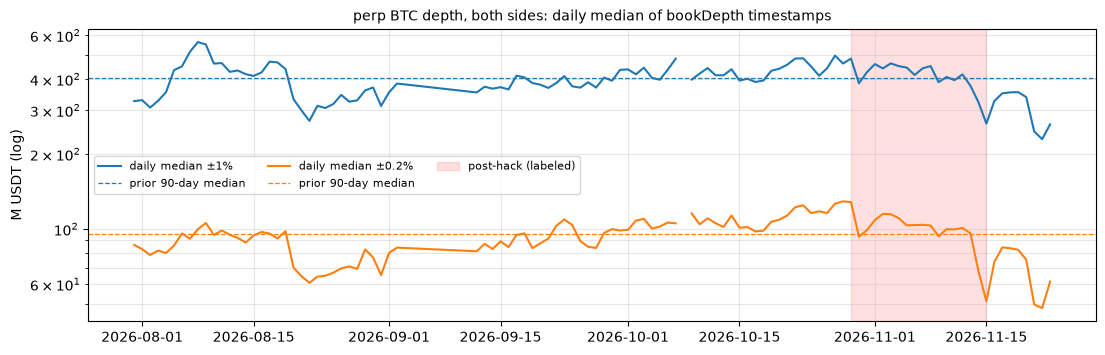

,0.2pct_total,1pct_total,0.2pct_total / prior 90-day median,1pct_total / prior 90-day median
day,,,,
2026-10-29 00:00:00+00:00,128.243,483.916,1.338,1.194
2026-10-30 00:00:00+00:00,92.986,384.858,0.970,0.949
2026-10-31 00:00:00+00:00,98.928,426.134,1.032,1.051
2026-11-01 00:00:00+00:00,108.591,459.728,1.133,1.134
2026-11-02 00:00:00+00:00,114.943,441.674,1.199,1.090
2026-11-03 00:00:00+00:00,114.603,462.704,1.195,1.141
2026-11-04 00:00:00+00:00,110.541,451.173,1.153,1.113
2026-11-05 00:00:00+00:00,103.388,445.008,1.078,1.098
2026-11-06 00:00:00+00:00,103.660,415.669,1.081,1.025


In [32]:
daily_bd = (bd_clean / USDT_M).resample("1D").median()
daily_bd.index.name = "day"
daily_bd = daily_bd[~daily_bd.index.isin(BAD_DAYS)]          # broken file days (section 5.1)
prior = daily_bd[(daily_bd.index >= POST_HACK[0] - pd.Timedelta(days=90)) & (daily_bd.index < POST_HACK[0])]
prior_median = prior.median()
hack_days = daily_bd[(daily_bd.index >= POST_HACK[0]) & (daily_bd.index <= POST_HACK[1])]
hack_table = pd.DataFrame({c: hack_days[c] for c in ("0.2pct_total", "1pct_total")})
for c in ("0.2pct_total", "1pct_total"):
    hack_table[f"{c} / prior 90-day median"] = hack_days[c] / prior_median[c]
print(f"prior 90 days {prior.index.min():%Y-%m-%d} -> {prior.index.max():%Y-%m-%d} ({len(prior)} usable days): median daily depth "
      f"±0.2% {prior_median['0.2pct_total']:.2f}, ±1% {prior_median['1pct_total']:.2f} M USDT")
print(f"post-hack {len(hack_days)} days: median of daily ratios ±0.2% "
      f"{hack_table['0.2pct_total / prior 90-day median'].median():.3f}, ±1% "
      f"{hack_table['1pct_total / prior 90-day median'].median():.3f}")

fig, ax = plt.subplots(figsize=(13, 3.8))
view = daily_bd[daily_bd.index >= POST_HACK[0] - pd.Timedelta(days=90)]
for c, color in (("1pct_total", "tab:blue"), ("0.2pct_total", "tab:orange")):
    ax.plot(view.index, view[c], color=color, label=f"daily median ±{c.split('_')[0].replace('pct', '%')}")
    ax.axhline(prior_median[c], color=color, ls="--", lw=0.9, label="prior 90-day median")
ax.axvspan(POST_HACK[0], POST_HACK[1] + pd.Timedelta(days=1), color="red", alpha=0.12, label="post-hack (labeled)")
ax.set_yscale("log")
ax.set_ylabel("M USDT (log)")
ax.set_title("perp BTC depth, both sides: daily median of bookDepth timestamps", fontsize=10)
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.3, which="both")
plt.show()
hack_table.round(3)

How to read it: the first line is the reference, the median daily depth of the 90 days before
2026-10-29 (the broken file days of September are left out, so fewer than 90 days count); the second, the median over the post-hack days of each day's depth divided by that
reference (1 = no change, 0.7 = 30% less). The plot shows the daily median depth (solid, log
scale, M USDT) from 90 days before the period to the end of the window, the reference as dashed
lines and the post-hack period shaded red. The table lists each post-hack day with its depth and
ratio to the reference.

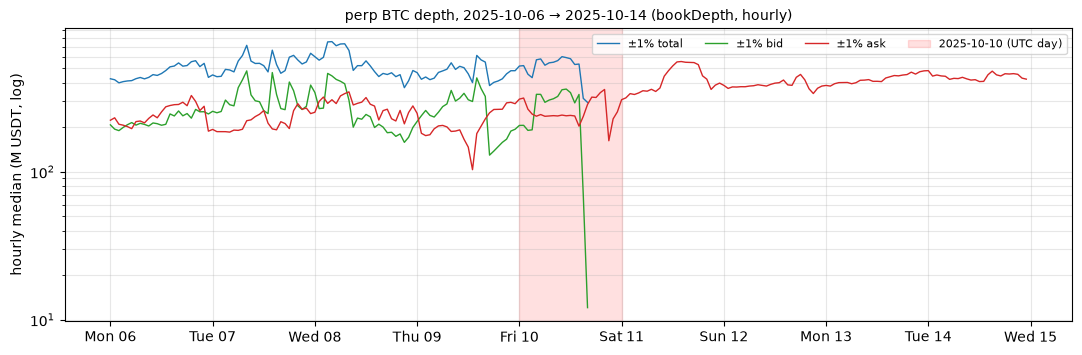

thinnest hour of the 9 days (±1% total): 2025-10-10 16:00 UTC (10:00 CDMX), 293.94 M USDT; normal 12-month median of hourly ±1% total: 340.15, p10 248.71


,1pct_total median,1pct_bid median,1pct_ask median,1pct_total min hour,1pct_bid min hour,1pct_ask min hour
hour_start_utc,,,,,,
2025-10-06 00:00:00+00:00,450.02,212.89,236.56,398.50,189.50,187.92
2025-10-07 00:00:00+00:00,536.43,290.30,212.11,438.46,247.05,185.17
2025-10-08 00:00:00+00:00,519.57,228.28,284.12,369.66,157.92,210.53
2025-10-09 00:00:00+00:00,467.72,255.82,201.84,382.00,129.47,103.23
2025-10-10 00:00:00+00:00,533.73,304.87,240.71,293.94,12.07,161.89
2025-10-11 00:00:00+00:00,NaN,NaN,390.74,NaN,NaN,306.71
2025-10-12 00:00:00+00:00,NaN,NaN,381.91,NaN,NaN,337.50
2025-10-13 00:00:00+00:00,NaN,NaN,415.15,NaN,NaN,378.88
2025-10-14 00:00:00+00:00,NaN,NaN,442.03,NaN,NaN,406.46


In [33]:
stress_h = bd_h[bd_h["period"] == "10/10 case"].set_index("hour_start_utc")
fig, ax = plt.subplots(figsize=(13, 3.8))
for c, color in (("1pct_total", "tab:blue"), ("1pct_bid", "tab:green"), ("1pct_ask", "tab:red")):
    ax.plot(stress_h.index, stress_h[c], color=color, lw=1, label=f"±{c.replace('pct_', '% ')}")
ten = pd.Timestamp("2025-10-10", tz="UTC")
ax.axvspan(ten, ten + pd.Timedelta(days=1), color="red", alpha=0.12, label="2025-10-10 (UTC day)")
ax.set_yscale("log")
ax.set_ylabel("hourly median (M USDT, log)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz="UTC"))
ax.set_title("perp BTC depth, 2025-10-06 → 2025-10-14 (bookDepth, hourly)", fontsize=10)
ax.legend(fontsize=8, ncol=4)
ax.grid(alpha=0.3, which="both")
plt.show()
ten_days = stress_h.groupby(stress_h.index.floor("D")).agg(
    **{f"{c} median": (c, "median") for c in ("1pct_total", "1pct_bid", "1pct_ask")},
    **{f"{c} min hour": (c, "min") for c in ("1pct_total", "1pct_bid", "1pct_ask")})
ten_low = stress_h["1pct_total"].idxmin()
print(f"thinnest hour of the 9 days (±1% total): {ten_low:%Y-%m-%d %H:%M} UTC "
      f"({ten_low.tz_convert('America/Mexico_City'):%H:%M} CDMX), {stress_h['1pct_total'].min():.2f} M USDT; "
      f"normal 12-month median of hourly ±1% total: {normal['1pct_total'].median():.2f}, p10 {normal['1pct_total'].quantile(0.1):.2f}")
ten_days.round(2)

How to read it: the plot shows the hourly median depth of the perp from 2025-10-06 to 2025-10-14
(log scale, M USDT): ±1% both sides (blue), ±1% bids alone (green, the side a forced seller
hits) and ±1% asks (red). The 2025 files have no ±0.2% rows. Where a line stops, that side was
**frozen** in the file (section 5.1) and is not shown: the ±1% bids are frozen from the afternoon
of 10 October to the end of the window, so **the bid side during and after the crash cannot be
measured from bookDepth**, and the bid values just before the freeze (the drop at 15–16 UTC) look
like the start of the same fault, not a measurement to trust. The UTC day of 10 October 2025 is shaded. The line below
gives the thinnest hour and compares it with the normal 12 months (outside this window). The table
has one row per day: the median hourly depth and the thinnest hour of that day.

## 6. Part 4 · Volume ≠ liquidity (1-minute spot candles, BTCUSDT and ETHUSDT)

**Volume** (USDT traded) and **range** ((high − low) / close of each hourly candle) describe
**activity and movement**, not cost: they say how much was traded and how far the price moved,
not how much could be traded at a given price. Same 12 months and same exclusion of the
post-hack weeks as Part 3. Hourly candles are built from the 1-minute ones.

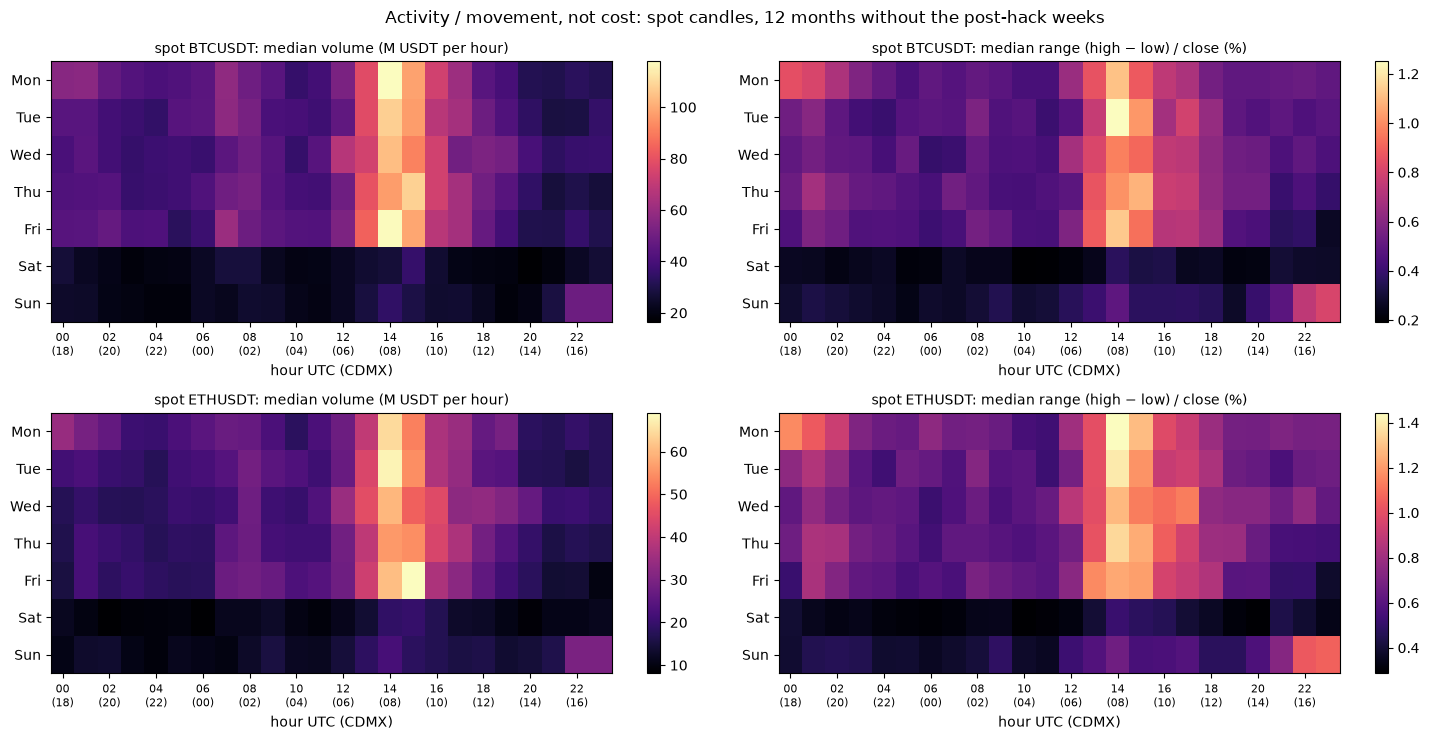

{'BTCUSDT': 8352, 'ETHUSDT': 8352} hourly candles


In [34]:
def hourly_candles(k):
    g = k.resample("1h")
    h = pd.DataFrame({"high": g["high"].max(), "low": g["low"].min(), "close": g["close"].last(),
                      "quote_volume": g["quote_volume"].sum(), "minutes": g.size()})
    h = h[h["minutes"] > 0]
    h["range_pct"] = (h["high"] - h["low"]) / h["close"] * 100
    h["volume_musdt"] = h["quote_volume"] / USDT_M
    h = add_time_labels(h.reset_index(), "open_time_utc")
    return h[~h["date_utc"].between(*POST_HACK)]


candles_h = {s: hourly_candles(k) for s, k in klines.items()}
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for row, (sym, h) in enumerate(candles_h.items()):
    for col, (c, title) in enumerate((("volume_musdt", "volume (M USDT per hour)"),
                                      ("range_pct", "range (high − low) / close (%)"))):
        t = week_heatmap(h, c)
        ax = axes[row, col]
        im = ax.imshow(t.to_numpy(), aspect="auto", cmap="magma")
        ax.set_yticks(range(7))
        ax.set_yticklabels(t.index)
        ax.set_xticks(range(0, 24, 2))
        ax.set_xticklabels([f"{x:02d}\n({int(cdmx_hour(x)):02d})" for x in range(0, 24, 2)], fontsize=8)
        ax.set_xlabel("hour UTC (CDMX)")
        ax.set_title(f"spot {sym}: median {title}", fontsize=10)
        fig.colorbar(im, ax=ax)
fig.suptitle("Activity / movement, not cost: spot candles, 12 months without the post-hack weeks")
fig.tight_layout()
plt.show()
print({s: len(h) for s, h in candles_h.items()}, "hourly candles")

How to read it: four heatmaps with the same layout as Part 3 (rows = UTC weekday, columns = UTC
hour with CDMX in brackets). Left: median USDT traded per hour (millions); right: median hourly
range in % of the price. Top BTC, bottom ETH. Bright = more volume / bigger moves. These are
**not** depth: compare where they are bright with where Part 3's depth heatmaps are bright.

,,points,Pearson corr,rank corr
comparison,perp depth band,,,
"volume vs depth, 24 hours",0.2% total,24,0.142,0.256
"range vs depth, 24 hours",0.2% total,24,-0.129,-0.430
"volume vs depth, 168 hour-of-week cells",0.2% total,168,-0.074,-0.098
"volume vs depth, 24 hours",1% total,24,0.229,0.260
"range vs depth, 24 hours",1% total,24,-0.053,-0.410
"volume vs depth, 168 hour-of-week cells",1% total,168,-0.098,-0.198


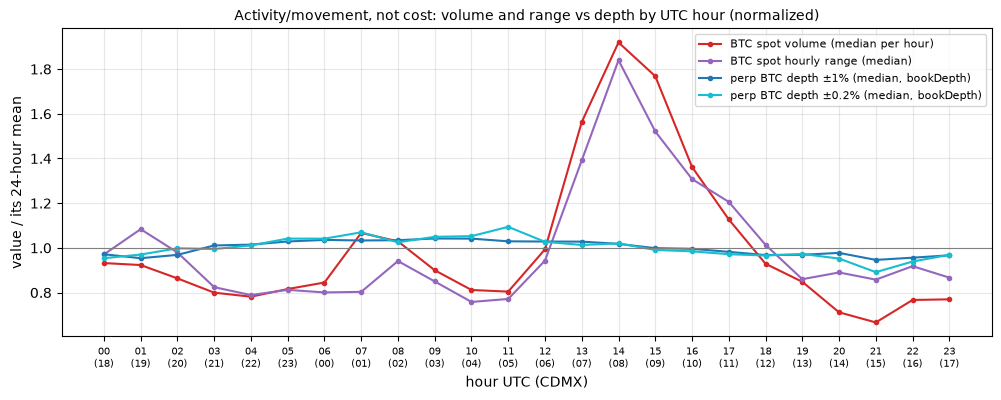

In [35]:
btc_h = candles_h["BTCUSDT"]
vol_prof = btc_h.groupby("hour_utc")["volume_musdt"].median()
rng_prof = btc_h.groupby("hour_utc")["range_pct"].median()
dep_prof = normal.groupby("hour_utc")[["0.2pct_total", "1pct_total"]].median()
vol_week = week_heatmap(btc_h, "volume_musdt").stack()
dep_week = {c: heat_all[c].stack() for c in ("0.2pct_total", "1pct_total")}
rows = []
for c in ("0.2pct_total", "1pct_total"):
    for name, x, y in (("volume vs depth, 24 hours", vol_prof, dep_prof[c]),
                       ("range vs depth, 24 hours", rng_prof, dep_prof[c]),
                       ("volume vs depth, 168 hour-of-week cells", vol_week, dep_week[c])):
        rows.append({"comparison": name, "perp depth band": c.replace("pct_", "% "), "points": len(x),
                     "Pearson corr": x.corr(y), "rank corr": x.rank().corr(y.rank())})
vol_vs_depth = pd.DataFrame(rows).set_index(["comparison", "perp depth band"])
display(vol_vs_depth.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for s, label, color in ((vol_prof, "BTC spot volume (median per hour)", "tab:red"),
                        (rng_prof, "BTC spot hourly range (median)", "tab:purple"),
                        (dep_prof["1pct_total"], "perp BTC depth ±1% (median, bookDepth)", "tab:blue"),
                        (dep_prof["0.2pct_total"], "perp BTC depth ±0.2% (median, bookDepth)", "tab:cyan")):
    ax.plot(s.index, s / s.mean(), marker=".", color=color, label=label)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(24)], fontsize=7)
ax.set_xlabel("hour UTC (CDMX)")
ax.set_ylabel("value / its 24-hour mean")
ax.set_title("Activity/movement, not cost: volume and range vs depth by UTC hour (normalized)", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

How to read it: the table correlates the **hour-of-day profiles** (24 points: the median of each
UTC hour over the normal 12 months) of BTC spot volume and range with the perp's depth, and the
168 weekday × hour medians of volume with those of depth. +1 = depth is high exactly when volume
is high; negative = depth is lower when volume is higher. Points are hours of the day, not
independent observations, so the correlations describe the shape of the profiles and are not a
test. The plot divides each profile by its own 24-hour mean so they share one axis: 1.5 = 50%
above that series' average hour.

## 7. Findings

One row per hypothesis: the number measured, how many observations it rests on, and what is
measured versus assumed. No causes are claimed here: the reasons in the hypothesis table were
written before the data and are not tested by these numbers.

In [36]:
ticks = json.loads((REPO_ROOT / "data" / "06_order_book" / "step0_checks.json").read_text())["ticks"]
run["spread_ticks"] = run["spread_usdt"] / run["market"].map(ticks)
one_tick = run.groupby(["market", "day", "hour_utc"])["spread_ticks"].apply(lambda s: 100 * (s.round(6) == 1).mean())
fee_share_100k = {m: 100 * rt_hourly.loc[(m, 100_000.0), "fee"] / rt_hourly.loc[(m, 100_000.0), "total"]
                  for m in (BTC_SPOT, ETH_SPOT)}
fee_share_1m = {m: 100 * rt_hourly.loc[(m, 1_000_000.0), "fee"] / rt_hourly.loc[(m, 1_000_000.0), "total"]
                for m in (BTC_SPOT, ETH_SPOT)}
c1 = "1pct_total"
findings = pd.DataFrame([
    {"H": "H1", "question": "Perp depth: weekdays 13-21 UTC vs weekend nights 21-03 UTC",
     "measured": f"ratio ±1% {ratios.loc[c1, 'business / weekend night']:.2f}, ±0.2% "
                 f"{ratios.loc['0.2pct_total', 'business / weekend night']:.2f}; months with ratio > 1 "
                 f"(±1%): {months_meeting[c1]} of {months_with_data[c1]}, (±0.2%): {months_meeting['0.2pct_total']} of {months_with_data['0.2pct_total']}; Tue 14 / Sun 03 (±1%) {ratios.loc[c1, 'Tue 14 / Sun 03']:.2f}",
     "n": f"{int(in_window(normal, **BUSINESS).sum())} vs {int(in_window(normal, **WEEKEND_NIGHT).sum())} hours, {len(by_month)} months",
     "measured vs assumed": "measured: bookDepth notional; assumed: its meaning (validated on 3 days, Part 1); post-hack excluded"},
    {"H": "H2", "question": "BTC/ETH spot spread ≈ 1 tick at every hour",
     "measured": f"lowest hourly share at 1 tick: BTC {one_tick.loc[BTC_SPOT].min():.1f}%, ETH {one_tick.loc[ETH_SPOT].min():.1f}%; "
                 f"highest hourly median spread BTC {hourly_run.loc[BTC_SPOT, 'spread med (bps)'].max():.4f} bps, "
                 f"ETH {hourly_run.loc[ETH_SPOT, 'spread med (bps)'].max():.4f} bps",
     "n": "48 hours × ~60 snapshots, 1 Sunday + 1 Monday",
     "measured vs assumed": "measured: collector snapshots; assumed: tick sizes of 2026-11-19 (notebook 06)"},
    {"H": "H3", "question": "Round trip fee-dominated at every hour up to 100k (BTC/ETH spot)",
     "measured": f"lowest hourly fee share at 100k: BTC {fee_share_100k[BTC_SPOT].min():.1f}%, ETH {fee_share_100k[ETH_SPOT].min():.1f}%; "
                 f"at 1M: BTC {fee_share_1m[BTC_SPOT].min():.1f}%, ETH {fee_share_1m[ETH_SPOT].min():.1f}%; "
                 f"PENGU 100k book part {cost_range.loc[(PENGU, '100,000'), 'spread+impact: lowest hourly median (bps)']:.1f}"
                 f"-{cost_range.loc[(PENGU, '100,000'), 'spread+impact: highest hourly median (bps)']:.1f} bps",
     "n": "48 hourly medians per size, 1 Sunday + 1 Monday",
     "measured vs assumed": "measured: book walk on snapshots; assumed: fees of notebook 07, impact = lower bound (frozen book)"},
    {"H": "H4", "question": "Spot and perp BTC depth move together by hour",
     "measured": f"corr ±0.1% {spot_perp.loc[(BTC_SPOT, '0.1%'), 'Pearson corr']:.2f}, ±0.2% "
                 f"{spot_perp.loc[(BTC_SPOT, '0.2%'), 'Pearson corr']:.2f}, ±1% {spot_perp.loc[(BTC_SPOT, '1%'), 'Pearson corr']:.2f}",
     "n": f"{int(spot_perp.loc[(BTC_SPOT, '0.1%'), 'hours'])} hourly medians (2 days)",
     "measured vs assumed": "measured: collector (±1% perp: bookDepth); hours are autocorrelated, so n overstates the evidence"},
    {"H": "H5", "question": "Thu 22 UTC (notebooks 06/07) was a typical hour",
     "measured": f"cell percentile among 168: ±1% {pct_rows[c1]['percentile among the 168 median cells']:.0f}, ±0.2% "
                 f"{pct_rows['0.2pct_total']['percentile among the 168 median cells']:.0f}; 2026-11-19 window vs Thu-22 hours: "
                 f"±1% p{pct_rows[c1]['its percentile among Thu 22 hours']:.0f}, ±0.2% p{pct_rows['0.2pct_total']['its percentile among Thu 22 hours']:.0f}",
     "n": f"{len(thu22)} Thursday-22 hours; {pct_rows[c1]['timestamps in that window']} timestamps in the window",
     "measured vs assumed": "measured: bookDepth; assumed: its meaning (Part 1)"},
    {"H": "H6", "question": "The thinnest hour (lowest p10) repeats across months",
     "measured": f"global worst hour ±1%: {hour_label(worst[c1])}; worst in {consistency[c1]['months where it is the worst hour']} "
                 f"of {consistency[c1]['months']} months, in the worst 3 in {consistency[c1]['months where it is in the worst 3']}; "
                 f"±0.2%: {hour_label(worst['0.2pct_total'])}, {consistency['0.2pct_total']['months where it is the worst hour']} / "
                 f"{consistency['0.2pct_total']['months where it is in the worst 3']}",
     "n": f"{len(normal)} normal hours, {consistency[c1]['months']} months (~30 values per hour and month)",
     "measured vs assumed": "measured: bookDepth; 'worst 3' criterion chosen post-inspection"},
    {"H": "H7", "question": "Volume is not a proxy for depth",
     "measured": f"corr BTC spot volume vs perp depth by hour (24 points): ±1% {vol_vs_depth.loc[('volume vs depth, 24 hours', '1% total'), 'Pearson corr']:.2f}, "
                 f"±0.2% {vol_vs_depth.loc[('volume vs depth, 24 hours', '0.2% total'), 'Pearson corr']:.2f}; 168 cells ±1% "
                 f"{vol_vs_depth.loc[('volume vs depth, 168 hour-of-week cells', '1% total'), 'Pearson corr']:.2f}",
     "n": "24 hour-of-day medians / 168 cells, 12 months",
     "measured vs assumed": "measured: candles and bookDepth; spot volume vs perp depth (different products)"},
]).set_index("H")
with pd.option_context("display.max_colwidth", 200):
    display(findings)

,question,measured,n,measured vs assumed
H,,,,
H1,Perp depth: weekdays 13-21 UTC vs weekend nights 21-03 UTC,"ratio ±1% 1.00, ±0.2% 1.03; months with ratio > 1 (±1%): 8 of 12, (±0.2%): 8 of 11; Tue 14 / Sun 03 (±1%) 0.97","1904 vs 582 hours, 12 months","measured: bookDepth notional; assumed: its meaning (validated on 3 days, Part 1); post-hack excluded"
H2,BTC/ETH spot spread ≈ 1 tick at every hour,"lowest hourly share at 1 tick: BTC 96.7%, ETH 98.3%; highest hourly median spread BTC 0.0017 bps, ETH 0.0604 bps","48 hours × ~60 snapshots, 1 Sunday + 1 Monday",measured: collector snapshots; assumed: tick sizes of 2026-11-19 (notebook 06)
H3,Round trip fee-dominated at every hour up to 100k (BTC/ETH spot),"lowest hourly fee share at 100k: BTC 95.3%, ETH 93.2%; at 1M: BTC 83.0%, ETH 72.3%; PENGU 100k book part 49.8-84.8 bps","48 hourly medians per size, 1 Sunday + 1 Monday","measured: book walk on snapshots; assumed: fees of notebook 07, impact = lower bound (frozen book)"
H4,Spot and perp BTC depth move together by hour,"corr ±0.1% 0.61, ±0.2% 0.47, ±1% 0.51",48 hourly medians (2 days),"measured: collector (±1% perp: bookDepth); hours are autocorrelated, so n overstates the evidence"
H5,Thu 22 UTC (notebooks 06/07) was a typical hour,"cell percentile among 168: ±1% 9, ±0.2% 14; 2026-11-19 window vs Thu-22 hours: ±1% p65, ±0.2% p69",46 Thursday-22 hours; 90 timestamps in the window,measured: bookDepth; assumed: its meaning (Part 1)
H6,The thinnest hour (lowest p10) repeats across months,"global worst hour ±1%: 22 UTC (16 CDMX); worst in 3 of 12 months, in the worst 3 in 8; ±0.2%: 22 UTC (16 CDMX), 5 / 10","8039 normal hours, 12 months (~30 values per hour and month)",measured: bookDepth; 'worst 3' criterion chosen post-inspection
H7,Volume is not a proxy for depth,"corr BTC spot volume vs perp depth by hour (24 points): ±1% 0.23, ±0.2% 0.14; 168 cells ±1% -0.10","24 hour-of-day medians / 168 cells, 12 months",measured: candles and bookDepth; spot volume vs perp depth (different products)


How to read it: one row per hypothesis of the introduction. `measured` gives the numbers this
notebook computed (each comes from a table above); `n` how many observations stand behind them;
the last column separates what was measured from what was assumed or chosen. Whether each number
supports or rejects the hypothesis is discussed in the key takeaways.

## Limitations

- **Two days of collector data.** Parts 0–2 rest on one Sunday and one Monday, and the run is
  labeled by the rule of Part 0 (see its output): a day with an unusually large range is not a
  typical day. Hour-to-hour differences of that run are one draw, not a pattern.
- **bookDepth is validated, not documented.** The four assumptions passed on three days (Part 1);
  they are assumed to hold on the other days. The files also have faults found here: an older
  format without ±0.2%, one day not published, short files, holes of minutes, and frozen or
  distorted stretches (section 5.1). The cleaning rules are post-inspection; section 5.2 shows the
  key numbers with and without them.
- **bookDepth is the perpetual only.** There is no free spot depth history, so every 12-month
  pattern is about the BTCUSDT perpetual; spot is only seen in the 48 h run. Part 4 compares spot
  volume with perp depth: two different products.
- **Depth is not cost.** Depth within ±0.2% / ±1% counts resting orders near the mid; it ignores
  hidden orders (RPI orders are not visible on USDⓈ-M), cancellations when an order arrives,
  and latency. Round-trip costs use frozen snapshots, so impact is a lower bound (notebook 07).
- **Hourly medians hide the worst minutes.** Each hourly bookDepth value is the median of ~120
  rows; a 2-minute hole in the book inside an hour barely moves it. p10 across days measures bad
  hours, not bad minutes.
- **Statistics are descriptive.** Correlations over 24 or 48 hourly points are not tests: hours are
  autocorrelated, and many cells and comparisons were looked at (the worst cell of 168 will look
  bad by chance alone).
- **No funding, no fees beyond notebook 07's.** The perp's cost here leaves out funding (M8).

## Conclusions (key takeaways)

Run: Binance, Saturday 2026-11-21 23:46 → Tuesday 2026-11-24 00:10 UTC, 2,905 snapshots per market,
0 failed; labeled **"stress weekend"** because Monday 2026-11-23's BTC range (6.88%, high 64,603,
low 60,386 USDT) was at the **94th percentile** of the previous 90 days (Sunday: range 4.74%,
p86; |return| p70). Patterns over 12 months: perp BTCUSDT bookDepth, 8,039 normal hours. No causes
are claimed.

1. **Binance's free `bookDepth` file measures what we measure, but needs cleaning before use.** Its
   ±0.2% depth matches our own perp snapshots with a median ratio of **0.997 (bids) and 0.996
   (asks)** and the best time shift is **0 h** (correlation 0.998); on notebook 06's day, **1.002 /
   0.994**. It is cumulative from the mid on every complete row, `depth` is in BTC, `notional` in
   USDT, negative % = bids. But ±0.2% only exists from **2026-01-15**, one day (**2026-10-08**) is
   missing, and frozen values affect up to **2.28%** of a column's rows; **11 days** were dropped
   (2026-03-20, 2026-04-22, 2026-09-03 → 09-11). During the 10/10 case the ±1% bids are frozen
   for **47.8%** of the rows, so the bid side of that crash cannot be measured from this file.
2. **H1 is rejected: the hour of the week barely changes the perpetual's depth.** Median ±1% depth
   on weekdays 13–21 UTC vs weekend nights 21–03 UTC: **335.1 vs 334.1 M USDT (ratio 1.003)**;
   ±0.2%: **1.025**. The ratio is above 1 in **8 of 12** months (±1%), with monthly values from
   **0.92 to 1.32**, and Tuesday 14 UTC / Sunday 03 UTC is **0.97**. The weekend-night book was not
   thinner than the business-hours book in this year. *(Same result without the cleaning: 1.004.)*
3. **H5 is rejected for the hour, not for the day: Thursday 22 UTC (16 CDMX) is one of the
   thinner hours of the week, but notebook 06/07's window was not thin.** The Thursday-22 cell is at
   the **9th percentile** of the 168 median cells (±1%; **14th** for ±0.2%). The hour with the
   lowest p10 is **22 UTC (16 CDMX)** for both bands (H6), and the worst cell is **Sunday 22 UTC**;
   22 UTC is the month's worst hour in only **3 of 12** months but among its worst 3 in **8 of 12**
   (±0.2%: **5** and **10 of 11**), so H6 holds loosely. The 2026-11-19 22:00–22:45 window itself
   had **338 M USDT** within ±1%, the **65th percentile** of the year's Thursday-22 hours.
4. **H2 and H3 hold through a stress day: for BTC and ETH, the hour changes the cost far less than
   the fee does.** The BTC spot spread was one tick in at least **96.7%** of the snapshots of every
   hour (ETH **98.3%**). For the taker → taker round trip at 100k USDT the fee was at least **95.3%**
   (BTC) and **93.2%** (ETH) of the median cost at every hour; at 1M, at least **83.0%** and
   **72.3%** (book part **1.9–4.1 bps** for BTC, **4.7–7.6 bps** for ETH, against a 20 bps fee).
   PENGU is where the hour shows: its 100k book part ranged **49.8–84.8 bps** across the 48 hours.
5. **Volume is not depth (H7 holds), and spot and perp depth only partly move together (H4).**
   Median BTC spot volume peaks at **14 UTC (08 CDMX) at 1.9× its daily mean**, while the perp's ±1%
   depth stays within about **±10%** of its mean all day; their 24-hour profiles correlate
   **0.23** (±1%) and the 168 hour-of-week cells **−0.10**. Within the 48 h run, BTC spot and perp
   depth correlated **0.61** at ±0.1% and **0.51** at ±1% (48 autocorrelated hours, 2 days); ETH and
   PENGU spot depth did not follow the perp (**−0.33** and **−0.55** at ±1%). The post-hack weeks
   (2026-10-29 → 11-14) were not thinner: daily ±1% depth was **1.05×** the median of the previous
   usable days.